# Week 1 – Exploratory Data Analysis on ShopSmart Retail Data

**Client:** ShopSmart Retail Ltd. · **Role:** Junior Data Scientist

## Purpose
ShopSmart has a year of customer, product, sales, inventory and returns data. Before any predictive model is built, management wants to
**understand the data, test its quality and find the patterns that matter**. This notebook is the complete, reproducible record of that work.

* Numbers quoted in the text are printed by the code, so they always match the results.
* Assumption: amounts are in Nigerian naira (₦). The data does not say so, but the stores are in Nigerian cities.

**Contents:** 1 Setup · 2 Load the data · 3 Clean the data · 4 KPIs (EDA) · 5 Charts · 6 Correlation · 7 Feature engineering · 8 Business questions · Summary

# Part 1 – Environment Setup

In [1]:
import os
import calendar
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import missingno as msno
from IPython.display import display

pd.set_option('display.max_columns', 50)
sns.set_theme(style='whitegrid')          

print('pandas', pd.__version__, '| numpy', np.__version__, '| seaborn', sns.__version__)

pandas 3.0.2 | numpy 2.4.4 | seaborn 0.13.2


In [2]:
# Using a relative folder name (Raw_Data) to ensure that  the notebook works anywhere, 
# as long as the CSV files sit in that folder next to the notebook. 

DATA_FOLDER = 'Raw_Data'     # the folder that contains the CSV files (relative path, so the notebook runs on any computer)
LIFESPAN_YEARS = 3           # assumption used later for the customer lifetime value approximation
os.makedirs('Cleaned_Data', exist_ok=True)       # cleaned data will be saved here
os.makedirs('Visualizations', exist_ok=True)     # charts will be saved here

def save_chart(filename):
    """Tidy the layout, save the current chart into the Visualizations folder, then show it."""
    plt.tight_layout()
    plt.savefig(os.path.join('Visualizations', filename), dpi=150, bbox_inches='tight')
    plt.show()

def millions(x, pos=None):
    """Axis label formatter: 25000000 -> '₦25m'."""
    return f'₦{x/1e6:,.0f}m'

# Part 2 – Load the Data

In [3]:
# I created a list of the names of the different datasets

files = ['ShopSmart_Orders.csv', 'ShopSmart_Order_Items.csv', 'ShopSmart_Inventory.csv',
         'ShopSmart_Suppliers.csv', 'ShopSmart_Products.csv', 'ShopSmart_Returns.csv',
         'ShopSmart_Stores.csv', 'ShopSmart_Employees.csv', 'ALA_ShopSmart_Customers.csv']

# creating an empty dictionary
data = {}
for file in files:
    # build a short name such as 'orders_df' from the file name, then read the file into that key
    name = file.replace('ShopSmart_', '').replace('ALA_', '').replace('.csv', '').lower() + '_df'
    data[name] = pd.read_csv(os.path.join(DATA_FOLDER, file))

print(list(data.keys()))

['orders_df', 'order_items_df', 'inventory_df', 'suppliers_df', 'products_df', 'returns_df', 'stores_df', 'employees_df', 'customers_df']


In [4]:
# Give every table its own variable name (same objects, just easier to type)
orders_df      = data['orders_df']
order_items_df = data['order_items_df']
inventory_df   = data['inventory_df']
suppliers_df   = data['suppliers_df']
products_df    = data['products_df']
returns_df     = data['returns_df']
stores_df      = data['stores_df']
employees_df   = data['employees_df']
customers_df   = data['customers_df']

### 2.1 Inspect every table
The brief asks for `head()`, `tail()`, `shape`, `columns`, data types and missing values for **every** CSV. The function below does this; the original left the loop commented out, so none of this output was visible.

In [5]:
def explore_df(df):
    print('1. Shape (rows, columns):', df.shape, '\n')
    print('2. Top 5 rows:')
    display(df.head())
    print('3. Bottom 5 rows:')
    display(df.tail())
    print('4. Columns:', list(df.columns), '\n')
    print('5. Data types:')
    print(df.dtypes, '\n')
    print('6. Missing values per column:')
    print(df.isna().sum())

for name in ['orders_df', 'order_items_df', 'customers_df']:
    print('=' * 70, '\n', name.upper(), '\n', '=' * 70)
    explore_df(data[name])

 ORDERS_DF 
1. Shape (rows, columns): (50000, 12) 

2. Top 5 rows:


,Order_ID,Customer_ID,Product_ID,Store_ID,Order_Date,Quantity,Unit_Price,Discount,Shipping_Cost,Payment_Method,Sales_Channel,Order_Status
0,ORD000001,CUST04572,PROD0244,STR005,7/19/2025,1,77989,10,3833,Card,Online,Completed
1,ORD000002,CUST04064,PROD0432,STR010,3/15/2025,3,11240,5,2872,Card,In-Store,Cancelled
2,ORD000003,CUST03435,PROD0052,STR004,10/1/2025,2,23595,20,922,Card,Online,Pending
3,ORD000004,CUST03536,PROD0051,STR023,7/15/2025,4,69922,5,911,Transfer,Online,Completed
4,ORD000005,CUST03676,PROD0356,STR021,3/28/2025,5,53344,0,1740,Card,Online,Cancelled


3. Bottom 5 rows:


,Order_ID,Customer_ID,Product_ID,Store_ID,Order_Date,Quantity,Unit_Price,Discount,Shipping_Cost,Payment_Method,Sales_Channel,Order_Status
49995,ORD049996,CUST02444,PROD0285,STR007,6/20/2025,3,83400,0,3807,Transfer,Online,Cancelled
49996,ORD049997,CUST02331,PROD0116,STR010,12/28/2025,4,23590,5,2735,Cash,In-Store,Completed
49997,ORD049998,CUST03580,PROD0252,STR004,1/20/2025,3,43552,10,2852,Transfer,Online,Pending
49998,ORD049999,CUST04995,PROD0369,STR002,7/16/2025,4,5307,20,1811,Card,Online,Cancelled
49999,ORD050000,CUST02696,PROD0167,STR002,4/21/2025,1,70765,0,754,Transfer,In-Store,Pending


4. Columns: ['Order_ID', 'Customer_ID', 'Product_ID', 'Store_ID', 'Order_Date', 'Quantity', 'Unit_Price', 'Discount', 'Shipping_Cost', 'Payment_Method', 'Sales_Channel', 'Order_Status'] 

5. Data types:
Order_ID            str
Customer_ID         str
Product_ID          str
Store_ID            str
Order_Date          str
Quantity          int64
Unit_Price        int64
Discount          int64
Shipping_Cost     int64
Payment_Method      str
Sales_Channel       str
Order_Status        str
dtype: object 

6. Missing values per column:


...

4. Columns: ['Order_Item_ID', 'Order_ID', 'Product_ID', 'Quantity', 'Unit_Price', 'Discount', 'Line_Total'] 

5. Data types:
Order_Item_ID      str
Order_ID           str
Product_ID         str
Quantity         int64
Unit_Price       int64
Discount         int64
Line_Total       int64
dtype: object 

6. Missing values per column:
Order_Item_ID    0
Order_ID         0
Product_ID       0
Quantity         0
Unit_Price       0
Discount         0
Line_Total       0
dtype: int64
 CUSTOMERS_DF 
1. Shape (rows, columns): (5000, 11) 

2. Top 5 rows:


,Customer_ID,First_Name,Last_Name,Gender,Age,Email,Phone,City,State,Registration_Date,Customer_Segment
0,CUST00001,Michelle,Russell,Male,65,elizabethfox@example.net,(701)981-5738x907,Abuja,Abuja,10/9/2023,Bronze
1,CUST00002,Sarah,Yu,Male,65,tfleming@example.com,6314323702,Kano,Kano,4/15/2023,Gold
2,CUST00003,Elizabeth,Adkins,Male,55,petertaylor@example.com,001-454-212-5805x0434,Asaba,Delta,3/8/2024,Bronze
3,CUST00004,Nicholas,Marshall,Male,31,kbean@example.net,001-513-728-5958x132,Lagos,Lagos,8/27/2023,Gold
4,CUST00005,Melinda,Patton,Male,53,mikaylajames@example.com,652-819-2186,Awka,Anambra,7/23/2023,Gold


3. Bottom 5 rows:


,Customer_ID,First_Name,Last_Name,Gender,Age,Email,Phone,City,State,Registration_Date,Customer_Segment
4995,CUST04996,William,Delgado,Female,63,valerie98@example.net,001-552-367-6268x989,Kano,Kano,9/21/2023,Bronze
4996,CUST04997,Ashley,Campbell,Male,43,danielmckee@example.net,460-419-1540,Port Harcourt,Rivers,8/6/2024,Gold
4997,CUST04998,Rebecca,Green,Male,66,jennifer26@example.com,477.407.6109x1571,Awka,Anambra,9/14/2024,Bronze
4998,CUST04999,Kathleen,Richards,Female,55,xmcdaniel@example.net,422.953.9359x7224,Port Harcourt,Rivers,4/6/2024,Silver
4999,CUST05000,Colleen,Anderson,Female,44,mendozamichelle@example.com,(278)379-9765x355,Kano,Kano,9/28/2023,Bronze


4. Columns: ['Customer_ID', 'First_Name', 'Last_Name', 'Gender', 'Age', 'Email', 'Phone', 'City', 'State', 'Registration_Date', 'Customer_Segment'] 

5. Data types:
Customer_ID            str
First_Name             str
Last_Name              str
Gender                 str
Age                  int64
Email                  str
Phone                  str
City                   str
State                  str
Registration_Date      str
Customer_Segment       str
dtype: object 

6. Missing values per column:
Customer_ID          0
First_Name           0
Last_Name            0
Gender               0
Age                  0
Email                0
Phone                0
City                 0
State                0
Registration_Date    0
Customer_Segment     0
dtype: int64


In [6]:
for name in ['products_df', 'stores_df', 'returns_df']:
    print('=' * 70, '\n', name.upper(), '\n', '=' * 70)
    explore_df(data[name])

 PRODUCTS_DF 
1. Shape (rows, columns): (500, 7) 

2. Top 5 rows:


,Product_ID,Product_Name,Category,Sub_Category,Brand,Cost_Price,Selling_Price
0,PROD0001,Beauty Item 1,Beauty,General,Zuniga PLC,44803,75526.21
1,PROD0002,Beauty Item 2,Beauty,General,Olson-Rosales,11728,14100.26
2,PROD0003,Electronics Item 3,Electronics,General,"Mosley, Watson and Middleton",39383,52368.82
3,PROD0004,Home Item 4,Home,General,Wood Ltd,8908,13574.07
4,PROD0005,Home Item 5,Home,General,Padilla-Blake,47918,84078.14


3. Bottom 5 rows:


,Product_ID,Product_Name,Category,Sub_Category,Brand,Cost_Price,Selling_Price
495,PROD0496,Fashion Item 496,Fashion,General,Mullen-Ward,34052,42759.48
496,PROD0497,Groceries Item 497,Groceries,General,"Brady, Rodriguez and Greer",14554,20132.43
497,PROD0498,Home Item 498,Home,General,Collins-Stewart,29958,33245.81
498,PROD0499,Fashion Item 499,Fashion,General,"Johnson, Brown and Strickland",6679,8434.13
499,PROD0500,Electronics Item 500,Electronics,General,Lucas and Sons,40152,44517.30


4. Columns: ['Product_ID', 'Product_Name', 'Category', 'Sub_Category', 'Brand', 'Cost_Price', 'Selling_Price'] 

5. Data types:
Product_ID           str
Product_Name         str
Category             str
Sub_Category         str
Brand                str
Cost_Price         int64
Selling_Price    float64
dtype: object 

6. Missing values per column:
Product_ID       0
Product_Name     0
Category         0
Sub_Category     0
Brand            0
Cost_Price       0
Selling_Price    0
dtype: int64
 STORES_DF 
1. Shape (rows, columns): (25, 6) 

2. Top 5 rows:


...

4. Columns: ['Store_ID', 'Store_Name', 'Region', 'State', 'City', 'Opening_Date'] 

5. Data types:
Store_ID        str
Store_Name      str
Region          str
State           str
City            str
Opening_Date    str
dtype: object 

6. Missing values per column:
Store_ID        0
Store_Name      0
Region          0
State           0
City            0
Opening_Date    0
dtype: int64
 RETURNS_DF 
1. Shape (rows, columns): (2500, 5) 

2. Top 5 rows:


,Return_ID,Order_ID,Return_Date,Return_Reason,Refund_Amount
0,RET00001,ORD035655,10/8/2025,Wrong Item,12433
1,RET00002,ORD037628,12/17/2025,Damaged,41722
2,RET00003,ORD046331,1/11/2025,Wrong Item,46937
3,RET00004,ORD019527,2/6/2025,Wrong Item,9943
4,RET00005,ORD022292,12/17/2025,Wrong Item,10350


3. Bottom 5 rows:


,Return_ID,Order_ID,Return_Date,Return_Reason,Refund_Amount
2495,RET02496,ORD028194,11/6/2025,Damaged,24782
2496,RET02497,ORD010872,9/7/2025,Damaged,27730
2497,RET02498,ORD006447,10/7/2025,Customer Changed Mind,12328
2498,RET02499,ORD024821,8/12/2025,Wrong Item,18366
2499,RET02500,ORD023048,3/12/2025,Customer Changed Mind,11615


4. Columns: ['Return_ID', 'Order_ID', 'Return_Date', 'Return_Reason', 'Refund_Amount'] 

5. Data types:
Return_ID          str
Order_ID           str
Return_Date        str
Return_Reason      str
Refund_Amount    int64
dtype: object 

6. Missing values per column:
Return_ID        0
Order_ID         0
Return_Date      0
Return_Reason    0
Refund_Amount    0
dtype: int64


In [7]:
for name in ['inventory_df', 'suppliers_df', 'employees_df']:
    print('=' * 70, '\n', name.upper(), '\n', '=' * 70)
    explore_df(data[name])

 INVENTORY_DF 
1. Shape (rows, columns): (500, 6) 

2. Top 5 rows:


,Inventory_ID,Product_ID,Store_ID,Stock_On_Hand,Reorder_Level,Last_Restock_Date
0,INV00001,PROD0001,STR002,94,26,8/16/2026
1,INV00002,PROD0002,STR021,338,17,8/27/2026
2,INV00003,PROD0003,STR007,178,27,9/26/2026
3,INV00004,PROD0004,STR004,482,38,8/30/2026
4,INV00005,PROD0005,STR015,76,16,9/21/2026


3. Bottom 5 rows:


,Inventory_ID,Product_ID,Store_ID,Stock_On_Hand,Reorder_Level,Last_Restock_Date
495,INV00496,PROD0496,STR006,94,45,10/6/2026
496,INV00497,PROD0497,STR002,93,22,8/10/2026
497,INV00498,PROD0498,STR001,45,6,8/19/2026
498,INV00499,PROD0499,STR020,99,16,9/23/2026
499,INV00500,PROD0500,STR020,424,23,9/2/2026


4. Columns: ['Inventory_ID', 'Product_ID', 'Store_ID', 'Stock_On_Hand', 'Reorder_Level', 'Last_Restock_Date'] 

5. Data types:
Inventory_ID           str
Product_ID             str
Store_ID               str
Stock_On_Hand        int64
Reorder_Level        int64
Last_Restock_Date      str
dtype: object 

6. Missing values per column:
Inventory_ID         0
Product_ID           0
Store_ID             0
Stock_On_Hand        0
Reorder_Level        0
Last_Restock_Date    0
dtype: int64
 SUPPLIERS_DF 
1. Shape (rows, columns): (489, 6) 

2. Top 5 rows:


...

4. Columns: ['Supplier_ID', 'Supplier_Name', 'Email', 'Phone', 'City', 'Country'] 

5. Data types:
Supplier_ID      str
Supplier_Name    str
Email            str
Phone            str
City             str
Country          str
dtype: object 

6. Missing values per column:
Supplier_ID      0
Supplier_Name    0
Email            0
Phone            0
City             0
Country          0
dtype: int64
 EMPLOYEES_DF 
1. Shape (rows, columns): (125, 6) 

2. Top 5 rows:


,Employee_ID,Employee_Name,Role,Store_ID,Hire_Date,Monthly_Salary
0,EMP0001,Keith Bennett,Inventory Officer,STR001,1/7/2019,4027
1,EMP0002,Aaron Chavez,Store Manager,STR001,5/30/2024,3355
2,EMP0003,Steven Wallace,Inventory Officer,STR001,5/19/2022,3160
3,EMP0004,Mia Jones,Customer Service,STR001,12/5/2023,4807
4,EMP0005,Ryan Miller,Inventory Officer,STR001,1/12/2022,3238


3. Bottom 5 rows:


,Employee_ID,Employee_Name,Role,Store_ID,Hire_Date,Monthly_Salary
120,EMP0121,Michelle Roberts,Customer Service,STR025,7/8/2025,3909
121,EMP0122,Debra Mckay,Customer Service,STR025,4/27/2023,2261
122,EMP0123,April West,Sales Associate,STR025,7/29/2020,4607
123,EMP0124,Ryan Mcdonald,Store Manager,STR025,6/7/2019,1825
124,EMP0125,Brian Smith,Customer Service,STR025,5/28/2026,4573


4. Columns: ['Employee_ID', 'Employee_Name', 'Role', 'Store_ID', 'Hire_Date', 'Monthly_Salary'] 

5. Data types:
Employee_ID         str
Employee_Name       str
Role                str
Store_ID            str
Hire_Date           str
Monthly_Salary    int64
dtype: object 

6. Missing values per column:
Employee_ID       0
Employee_Name     0
Role              0
Store_ID          0
Hire_Date         0
Monthly_Salary    0
dtype: int64


### 2.2 Missing values – one summary for all tables

,rows,columns,total_missing_values
orders_df,50000,12,0
order_items_df,50000,7,0
inventory_df,500,6,0
suppliers_df,489,6,0
products_df,500,7,0
returns_df,2500,5,0
stores_df,25,6,0
employees_df,125,6,0
customers_df,5000,11,0


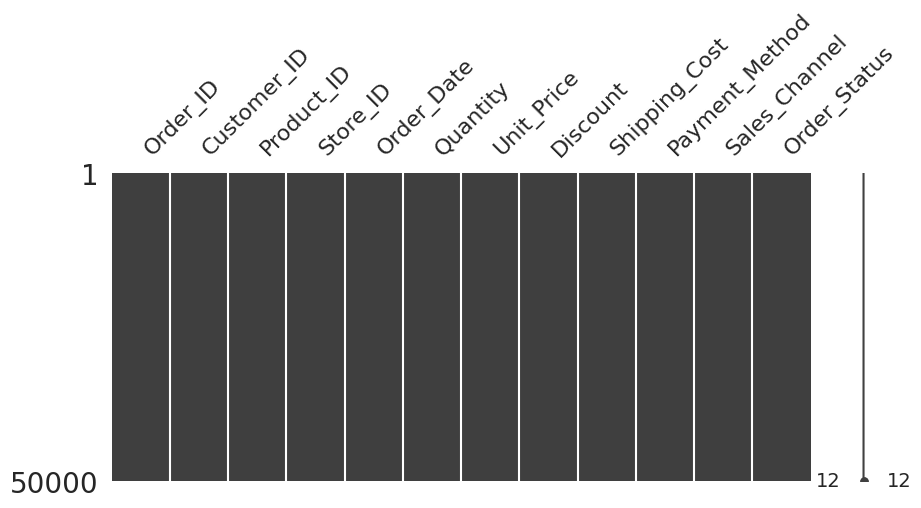

In [8]:
missing_summary = pd.DataFrame({
    'rows': {name: df.shape[0] for name, df in data.items()},
    'columns': {name: df.shape[1] for name, df in data.items()},
    'total_missing_values': {name: int(df.isna().sum().sum()) for name, df in data.items()},
})
display(missing_summary)

# a picture of completeness for the biggest table (a solid black bar = no gaps)
msno.matrix(orders_df, figsize=(10, 4))
plt.show()

**Finding:** none of the nine tables has a missing value. That does *not* mean the data is correct – Part 3 shows several logic problems that `isna()` cannot see.

---
# Part 3 – Data Cleaning

The brief lists six tasks: **remove duplicates · handle missing values · fix data types · convert dates · rename columns · check inconsistent values**, and asks us to *document every step*.
I record each step in a small list called `cleaning_log` and display it at the end of this part.

**Rule followed:** fix what is clearly wrong, but **flag** (do not delete) records that look suspicious. Deleting rows changes the totals, and we often cannot tell which field is wrong.

In [9]:
cleaning_log = []     # every cleaning step is added here

def log_step(table, task, finding, action):
    """Add one line to the cleaning log."""
    cleaning_log.append({'table': table, 'task': task, 'finding': finding, 'action': action})

### 3.1 Remove duplicates
Check two things in every table: completely repeated rows, and repeated ID values (the first column is always the ID).

In [10]:
for name, df in data.items():
    id_col = df.columns[0]
    n_rows_dup = df.duplicated().sum()
    n_id_dup = df[id_col].duplicated().sum()
    print(f'{name:<16} duplicate rows: {n_rows_dup} | repeated {id_col}: {n_id_dup}')
    log_step(name, 'Remove duplicates', f'{n_rows_dup} duplicate rows, {n_id_dup} repeated {id_col}', 'Nothing to remove' if n_rows_dup == 0 else 'Removed')

orders_df        duplicate rows: 0 | repeated Order_ID: 0
order_items_df   duplicate rows: 0 | repeated Order_Item_ID: 0
inventory_df     duplicate rows: 0 | repeated Inventory_ID: 0
suppliers_df     duplicate rows: 0 | repeated Supplier_ID: 0
products_df      duplicate rows: 0 | repeated Product_ID: 0
returns_df       duplicate rows: 0 | repeated Return_ID: 0
stores_df        duplicate rows: 0 | repeated Store_ID: 0
employees_df     duplicate rows: 0 | repeated Employee_ID: 0
customers_df     duplicate rows: 0 | repeated Customer_ID: 0


No table has duplicate rows. (Note: `Order_ID` *is* repeated inside the returns table – that is a different issue, handled in 3.6.)

### 3.2 Handle missing values
From Part 2 there are no missing values, so nothing needs filling or dropping. One column worth a look is the customer phone number.

In [11]:
digits = customers_df['Phone'].str.replace(r'\D', '', regex=True)     # keep only the digits
short_phones = (digits.str.len() < 7).sum()
print('Customer phone numbers with fewer than 7 digits:', short_phones)
print('Example formats:', customers_df['Phone'].sample(4, random_state=1).tolist())
log_step('customers_df', 'Missing values', 'No blanks. Phone numbers use many formats and some are very short', 'Left as supplied: phone numbers are not used in any analysis')
for name in data:
    log_step(name, 'Missing values', 'No missing values found', 'No action needed')

Customer phone numbers with fewer than 7 digits: 186
Example formats: ['(339)642-1483x11302', '470.903.8905x110', '(545)847-4197x237', '001-516-863-5825x19354']




### 3.3 Rename columns
Column names such as `Order_ID` and `Unit_Price` mix capital letters. Lower-case names are easier to type and avoid mistakes. I also give the repeated names (`City`, `State`, `Email`, `Phone`) a clear prefix, so after merging tables we do not need messy suffixes such as `_customers` or `_for_inventory`.

In [12]:
for name, df in data.items():
    df.columns = df.columns.str.strip().str.lower()          # 'Order_ID ' -> 'order_id'

customers_df = customers_df.rename(columns={'city': 'customer_city', 'state': 'customer_state', 'email': 'customer_email', 'phone': 'customer_phone'})
stores_df    = stores_df.rename(columns={'city': 'store_city', 'state': 'store_state'})
suppliers_df = suppliers_df.rename(columns={'city': 'supplier_city', 'country': 'supplier_country', 'email': 'supplier_email', 'phone': 'supplier_phone'})

print('orders_df   :', list(orders_df.columns))
print('customers_df:', list(customers_df.columns))
print('stores_df   :', list(stores_df.columns))
for name in data:
    log_step(name, 'Rename columns', 'Mixed-case column names', 'Converted to lower case')
log_step('customers_df / stores_df / suppliers_df', 'Rename columns', 'city, state, email, phone appear in several tables', 'Added prefixes (customer_, store_, supplier_)')

orders_df   : ['order_id', 'customer_id', 'product_id', 'store_id', 'order_date', 'quantity', 'unit_price', 'discount', 'shipping_cost', 'payment_method', 'sales_channel', 'order_status']
customers_df: ['customer_id', 'first_name', 'last_name', 'gender', 'age', 'customer_email', 'customer_phone', 'customer_city', 'customer_state', 'registration_date', 'customer_segment']
stores_df   : ['store_id', 'store_name', 'region', 'store_state', 'store_city', 'opening_date']


### 3.4 Fix data types and convert dates
All dates were stored as text. I convert them with an **explicit format** (`%m/%d/%Y`, month first). Without a format, a date like `3/8/2025` could be read as 3 August or 8 March.
The file proves it is month-first because dates such as `7/19/2025` exist (there is no 19th month).

In [13]:
orders_df['order_date']             = pd.to_datetime(orders_df['order_date'], format='%m/%d/%Y')
customers_df['registration_date']   = pd.to_datetime(customers_df['registration_date'], format='%m/%d/%Y')
returns_df['return_date']           = pd.to_datetime(returns_df['return_date'], format='%m/%d/%Y')
stores_df['opening_date']           = pd.to_datetime(stores_df['opening_date'], format='%m/%d/%Y')
employees_df['hire_date']           = pd.to_datetime(employees_df['hire_date'], format='%m/%d/%Y')
inventory_df['last_restock_date']   = pd.to_datetime(inventory_df['last_restock_date'], format='%m/%d/%Y')

# columns that repeat a small set of labels are better stored as 'category'
for col in ['payment_method', 'sales_channel', 'order_status']:
    orders_df[col] = orders_df[col].astype('category')
customers_df['customer_segment'] = pd.Categorical(customers_df['customer_segment'], categories=['Bronze', 'Silver', 'Gold'], ordered=True)   # Bronze < Silver < Gold
customers_df['gender'] = customers_df['gender'].astype('category')
products_df['category'] = products_df['category'].astype('category')
returns_df['return_reason'] = returns_df['return_reason'].astype('category')

print('Order dates run from', orders_df['order_date'].min().date(), 'to', orders_df['order_date'].max().date())
log_step('6 tables', 'Convert dates', 'Date columns stored as text', 'Converted to datetime with format %m/%d/%Y')
log_step('orders / customers / products / returns', 'Fix data types', 'Label columns stored as text', 'Converted to category (customer_segment is ordered)')
orders_df.info()

Order dates run from 2025-01-01 to 2025-12-31
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   order_id        50000 non-null  str           
 1   customer_id     50000 non-null  str           
 2   product_id      50000 non-null  str           
 3   store_id        50000 non-null  str           
 4   order_date      50000 non-null  datetime64[us]
 5   quantity        50000 non-null  int64         
 6   unit_price      50000 non-null  int64         
 7   discount        50000 non-null  int64         
 8   shipping_cost   50000 non-null  int64         
 9   payment_method  50000 non-null  category      
 10  sales_channel   50000 non-null  category      
 11  order_status    50000 non-null  category      
dtypes: category(3), datetime64[us](1), int64(4), str(4)
memory usage: 3.6 MB



### 3.5 Orders and Order_Items – are they really two different tables?
Before merging, check whether `order_items_df` adds any new information to `orders_df`.

In [14]:
check = orders_df.merge(order_items_df, on='order_id', suffixes=('', '_item'))
print('Rows after merging on order_id alone:', len(check), '(orders has', len(orders_df), 'rows)')
for col in ['product_id', 'quantity', 'unit_price', 'discount']:
    print(f'{col:<12} rows that differ between the two tables: {(check[col] != check[col + "_item"]).sum()}')

Rows after merging on order_id alone: 50000 (orders has 50000 rows)
product_id   rows that differ between the two tables: 0
quantity     rows that differ between the two tables: 0
unit_price   rows that differ between the two tables: 0
discount     rows that differ between the two tables: 0


Every order appears **once** in each table and the product, quantity, price and discount are identical. So `order_items_df` is a copy of `orders_df` that only adds `line_total`.
We will therefore bring in just `line_total` (merge on `order_id` only) instead of joining on five columns.

How is `line_total` calculated?

In [15]:
check['line_total_calc'] = check['quantity'] * check['unit_price'] - check['discount']      # our own calculation, using the discount as a flat amount
matches_flat = (check['line_total'] == check['line_total_calc']).mean()
print(f'line_total = quantity x unit_price - discount, in {matches_flat:.1%} of rows')
print('Discount values found:', sorted(orders_df['discount'].unique()))
log_step('orders_df / order_items_df', 'Inconsistent values', 'Order_Items repeats Orders exactly and only adds line_total', 'Merge only line_total on order_id')
log_step('orders_df', 'Inconsistent values', 'line_total subtracts the discount as a flat amount (0-20 naira), not a percentage', 'Kept line_total as recorded; flagged for the client to confirm the unit')

line_total = quantity x unit_price - discount, in 100.0% of rows
Discount values found: [np.int64(0), np.int64(5), np.int64(10), np.int64(15), np.int64(20)]


`line_total` subtracts the discount (0, 5, 10, 15 or 20) as a **flat amount of naira**. On a ₦150,000 order that is almost nothing. If the discount was meant to be a **percentage**, revenue would be much lower.
I keep `line_total` as recorded (it is the figure in the source data) and flag this as a question for the client.

### 3.6 Check for inconsistent values
Logic checks across tables. For each problem I add a `flag_` column (True/False) so the rows are kept but can be filtered out.

In [16]:
# spelling of labels: each label should appear in a small, clean list 
for col in ['payment_method', 'sales_channel', 'order_status']:
    print(orders_df[col].value_counts().to_dict())
print(products_df['category'].value_counts().to_dict())
print(customers_df['customer_segment'].value_counts().to_dict())

{'Card': 16741, 'Cash': 16693, 'Transfer': 16566}
{'In-Store': 25018, 'Online': 24982}
{'Cancelled': 16861, 'Pending': 16610, 'Completed': 16529}
{'Beauty': 119, 'Groceries': 102, 'Electronics': 99, 'Fashion': 94, 'Home': 86}
{'Gold': 1691, 'Silver': 1674, 'Bronze': 1635}


In [17]:
# price checks: is any order sold below the product's cost price? 
# .map() works like VLOOKUP in Excel: look up each order's product_id in the products table
orders_df['cost_price'] = orders_df['product_id'].map(products_df.set_index('product_id')['cost_price'])
orders_df['flag_below_cost'] = orders_df['unit_price'] < orders_df['cost_price']
print('Orders sold below the product cost price:', orders_df['flag_below_cost'].sum(), f'({orders_df["flag_below_cost"].mean():.1%})')

# did customers order before they registered? 
orders_df['registration_date'] = orders_df['customer_id'].map(customers_df.set_index('customer_id')['registration_date'])
orders_df['flag_order_before_registration'] = orders_df['order_date'] < orders_df['registration_date']
print('Orders placed before the customer registered:', orders_df['flag_order_before_registration'].sum())
orders_df = orders_df.drop(columns=['registration_date'])      # only needed for the check

Orders sold below the product cost price: 12163 (24.3%)
Orders placed before the customer registered: 5159


In [18]:
# returns: do the dates and amounts make sense?
returns_df['order_date']   = returns_df['order_id'].map(orders_df.set_index('order_id')['order_date'])
returns_df['order_status'] = returns_df['order_id'].map(orders_df.set_index('order_id')['order_status'])
returns_df['order_total']  = returns_df['order_id'].map(order_items_df.set_index('order_id')['line_total'])

returns_df['flag_return_before_order'] = returns_df['return_date'] < returns_df['order_date']
returns_df['flag_refund_bigger_than_sale'] = returns_df['refund_amount'] > returns_df['order_total']
returns_df['flag_order_not_completed'] = returns_df['order_status'].astype(str) != 'Completed'
returns_df['flag_order_returned_twice'] = returns_df['order_id'].duplicated(keep=False)

for col in ['flag_return_before_order', 'flag_refund_bigger_than_sale', 'flag_order_not_completed', 'flag_order_returned_twice']:
    print(f'{col:<32} {returns_df[col].sum():>5} of {len(returns_df)} returns ({returns_df[col].mean():.0%})')

flag_return_before_order          1252 of 2500 returns (50%)
flag_refund_bigger_than_sale       270 of 2500 returns (11%)
flag_order_not_completed          1685 of 2500 returns (67%)
flag_order_returned_twice          114 of 2500 returns (5%)


Half of the return dates are **before** the order date, about two-thirds of returns are for orders that were never completed, and some refunds are larger than the sale. These are impossible in real life. I cannot know which field is wrong, so the rows are kept and flagged.

In [19]:
# stores: names and regions 
print(stores_df['store_name'].value_counts().head(5).to_string(), '\n')
stores_df['store_label'] = stores_df['store_id'] + ' ' + stores_df['store_city']      # a unique, readable name for charts
print('Region of each store in Abuja:', stores_df.loc[stores_df['store_city'] == 'Abuja', 'region'].tolist())

# gender vs first name
common_names = customers_df['first_name'].value_counts().head(4).index
display(pd.crosstab(customers_df.loc[customers_df['first_name'].isin(common_names), 'first_name'], customers_df['gender']))

# suppliers link to products through the brand name 
suppliers_df['supplier_brand'] = suppliers_df['supplier_name'].str.replace(' Supplies', '', regex=False)
print('Suppliers whose brand exists in the products table:', suppliers_df['supplier_brand'].isin(products_df['brand']).mean())

store_name
ShopSmart Abuja     4
ShopSmart Lagos     4
ShopSmart Ibadan    4
ShopSmart Asaba     3
ShopSmart Kaduna    3 

Region of each store in Abuja: ['East', 'North', 'South', 'South']


gender,Female,Male
first_name,,
David,28,51
James,33,41
Jennifer,29,35
Michael,59,61


Suppliers whose brand exists in the products table: 1.0


* **Store names repeat** (four stores are all called "ShopSmart Abuja"), so grouping by `store_name` silently merges stores. Always group by `store_id` (or the unique `store_label` made above).
* **Region is not geographic:** the Abuja stores sit in different regions. I report regions as supplied but also use store state.
* **Gender is unreliable:** common names such as Jennifer appear under both genders in similar numbers (see the table above), so gender is not used for any conclusion.
* **Suppliers** have no supplier ID in the products table, but the supplier name is the brand name plus " Supplies". That gives us a link (used in Q7).


### 3.7 The cleaning log (documentation of every step) and saving the cleaned tables

In [20]:
cleaning_log.extend([
    {'table': 'orders_df', 'task': 'Inconsistent values', 'finding': 'Orders sold below the product cost price', 'action': 'Added flag_below_cost'},
    {'table': 'orders_df', 'task': 'Inconsistent values', 'finding': 'Orders dated before the customer registered', 'action': 'Added flag_order_before_registration'},
    {'table': 'returns_df', 'task': 'Inconsistent values', 'finding': 'Return before order, refund above sale value, return on uncompleted order, order returned twice', 'action': 'Added four flag_ columns; rows kept'},
    {'table': 'stores_df', 'task': 'Inconsistent values', 'finding': 'Store names repeat; region is not geographic', 'action': 'Created unique store_label; analyse by store_id'},
    {'table': 'customers_df', 'task': 'Inconsistent values', 'finding': 'Gender label does not match first names', 'action': 'Not used in conclusions'},
    {'table': 'suppliers_df', 'task': 'Inconsistent values', 'finding': 'No supplier ID in products', 'action': 'Created supplier_brand to link suppliers to products'},
])
cleaning_log_df = pd.DataFrame(cleaning_log)
print(len(cleaning_log_df), 'documented steps. Steps per task:')
display(cleaning_log_df['task'].value_counts().to_frame('steps'))
with pd.option_context('display.max_colwidth', 120):
    display(cleaning_log_df[~cleaning_log_df['task'].isin(['Missing values', 'Rename columns', 'Remove duplicates'])])

cleaning_log_df.to_csv('Cleaned_Data/Cleaning_Log.csv', index=False)
cleaned_tables = {'orders': orders_df, 'order_items': order_items_df, 'customers': customers_df, 'products': products_df, 'stores': stores_df,
                  'returns': returns_df, 'employees': employees_df, 'suppliers': suppliers_df, 'inventory': inventory_df}
for name, df in cleaned_tables.items():
    df.to_csv(f'Cleaned_Data/{name}_clean.csv', index=False)
print('Saved', len(cleaned_tables), 'cleaned tables to the Cleaned_Data folder. No rows were deleted.')

39 documented steps. Steps per task:


,steps
task,
Missing values,10
Rename columns,10
Remove duplicates,9
Inconsistent values,8
Convert dates,1
Fix data types,1


,table,task,finding,action
29,6 tables,Convert dates,Date columns stored as text,Converted to datetime with format %m/%d/%Y
30,orders / customers / products / returns,Fix data types,Label columns stored as text,Converted to category (customer_segment is ordered)
31,orders_df / order_items_df,Inconsistent values,Order_Items repeats Orders exactly and only adds line_total,Merge only line_total on order_id
32,orders_df,Inconsistent values,"line_total subtracts the discount as a flat amount (0-20 naira), not a percentage",Kept line_total as recorded; flagged for the client to confirm the unit
33,orders_df,Inconsistent values,Orders sold below the product cost price,Added flag_below_cost
34,orders_df,Inconsistent values,Orders dated before the customer registered,Added flag_order_before_registration
35,returns_df,Inconsistent values,"Return before order, refund above sale value, return on uncompleted order, order returned twice",Added four flag_ columns; rows kept
36,stores_df,Inconsistent values,Store names repeat; region is not geographic,Created unique store_label; analyse by store_id
37,customers_df,Inconsistent values,Gender label does not match first names,Not used in conclusions
38,suppliers_df,Inconsistent values,No supplier ID in products,Created supplier_brand to link suppliers to products


Saved 9 cleaned tables to the Cleaned_Data folder. No rows were deleted.


---
# Part 4 – Exploratory Data Analysis: KPIs

### 4.1 Build the analysis tables (merging)


In [21]:
# Sales table: one row per order (50,000 rows) 
sales_df = (orders_df
            .merge(order_items_df[['order_id', 'line_total']], on='order_id')
            .merge(products_df[['product_id', 'product_name', 'category', 'brand', 'selling_price']], on='product_id')
            .merge(stores_df[['store_id', 'store_label', 'store_name', 'region', 'store_state', 'store_city']], on='store_id')
            .merge(customers_df[['customer_id', 'age', 'customer_segment', 'customer_state']], on='customer_id'))

# Returns: some orders were returned twice, so add up the returns PER ORDER first, then attach 
refunds_per_order = returns_df.groupby('order_id')['refund_amount'].sum()
sales_df['returned'] = sales_df['order_id'].isin(returns_df['order_id'])
sales_df['refund_amount'] = sales_df['order_id'].map(refunds_per_order).fillna(0)

# Month columns (needed for the monthly charts)
month_names = list(calendar.month_name)[1:]                     # ['January', ..., 'December']
sales_df['order_month'] = pd.Categorical(sales_df['order_date'].dt.month_name(), categories=month_names, ordered=True)

print('Shape of sales_df:', sales_df.shape)
assert len(sales_df) == len(orders_df) == 50000, 'A merge changed the number of orders!'
assert sales_df['order_id'].is_unique

Shape of sales_df: (50000, 31)


The `assert` lines are a safety net: if a merge ever adds or loses rows, the notebook stops with an error instead of quietly giving wrong totals.
(The original `join_df` happened to keep 50,000 rows, but the later `outer` merge with returns produced **50,058** rows, double-counting 58 orders; see Part 7.)

### 4.2 Which orders count as revenue?
`order_status` has three values in almost equal shares. Your original choice – *revenue = Completed orders* – is sensible. The problem was **consistency**: the original used Completed orders for Total Revenue and Total Quantity, but *all* orders for Average Order Value, the monthly chart, the top-10 chart and the age chart.
Mixed bases give numbers that do not fit together. Here I define `completed_df` once and use it for every revenue figure, and I say clearly where *all* orders are used instead.

In [22]:
completed_df = sales_df[sales_df['order_status'] == 'Completed'].copy()

status_table = sales_df.groupby('order_status', observed=True).agg(orders=('order_id', 'count'), booked_value=('line_total', 'sum'))
status_table['share_of_value_%'] = status_table['booked_value'] / status_table['booked_value'].sum() * 100
display(status_table.style.format({'orders': '{:,.0f}', 'booked_value': '{:,.0f}', 'share_of_value_%': '{:.1f}%'}))
print(f'Only {len(completed_df):,} of {len(sales_df):,} orders are Completed.')

,orders,booked_value,share_of_value_%
order_status,,,
Cancelled,"16,861","2,552,391,921",33.7%
Completed,"16,529","2,496,824,383",33.0%
Pending,"16,610","2,526,033,782",33.3%


Only 16,529 of 50,000 orders are Completed.


### 4.3 The required KPIs
Each KPI has a one-line definition so the reader knows exactly what was calculated.

In [23]:
# Inventory table: one row per product, at the right grain
inventory_analysis_df = (inventory_df
                         .merge(products_df[['product_id', 'product_name', 'category', 'cost_price', 'selling_price']], on='product_id')
                         .merge(stores_df[['store_id', 'store_label']], on='store_id'))
inventory_analysis_df['stock_value_at_cost'] = inventory_analysis_df['stock_on_hand'] * inventory_analysis_df['cost_price']

total_revenue_completed = completed_df['line_total'].sum()
total_revenue_all       = sales_df['line_total'].sum()
refunds_completed       = completed_df['refund_amount'].sum()

kpi = pd.DataFrame([
    ('Total Revenue (Completed orders)',        f'{total_revenue_completed:,.0f}',                    'Sum of line_total for Completed orders'),
    ('   Net of refunds',                       f'{total_revenue_completed - refunds_completed:,.0f}', 'Revenue minus refunds on Completed orders'),
    ('   For comparison: all orders booked',    f'{total_revenue_all:,.0f}',                          'Sum of line_total for every order, including Pending and Cancelled'),
    ('Total Customers',                         f'{customers_df["customer_id"].nunique():,}',         'Unique IDs in the customers table'),
    ('Total Products',                          f'{products_df["product_id"].nunique():,}',           'Unique IDs in the products table'),
    ('Total Stores',                            f'{stores_df["store_id"].nunique():,}',               'Unique IDs in the stores table'),
    ('Total Orders (all)',                      f'{sales_df["order_id"].nunique():,}',                'Unique order IDs'),
    ('   Completed orders',                     f'{completed_df["order_id"].nunique():,}',            'Unique order IDs with status Completed'),
    ('Average Order Value (Completed)',         f'{total_revenue_completed / completed_df["order_id"].nunique():,.0f}', 'Completed revenue / completed orders (same base as revenue)'),
    ('Average Selling Price (catalogue)',       f'{products_df["selling_price"].mean():,.0f}',        'Mean selling_price over the 500 products'),
    ('Average Selling Price (charged per unit)', f'{total_revenue_completed / completed_df["quantity"].sum():,.0f}', 'Completed revenue / units sold'),
    ('Total Quantity Sold (Completed)',         f'{completed_df["quantity"].sum():,}',                'Sum of quantity on Completed orders'),
    ('Return Rate (all orders)',                f'{returns_df["order_id"].nunique() / len(sales_df) * 100:.2f}%', 'Orders with at least one return / all orders'),
    ('   Return Rate (Completed orders)',       f'{completed_df["returned"].mean() * 100:.2f}%',      'Completed orders with a return / Completed orders'),
    ('Inventory Value (at cost)',               f'{inventory_analysis_df["stock_value_at_cost"].sum():,.0f}', 'Sum of stock_on_hand x cost_price, from the INVENTORY table'),
], columns=['KPI', 'Value (₦ where money)', 'Definition'])
with pd.option_context('display.max_colwidth', 100):
    display(kpi)
kpi.to_csv('Cleaned_Data/kpi_table.csv', index=False)

,KPI,Value (₦ where money),Definition
0,Total Revenue (Completed orders),"2,496,824,383",Sum of line_total for Completed orders
1,Net of refunds,"2,475,234,402",Revenue minus refunds on Completed orders
2,For comparison: all orders booked,"7,575,250,086","Sum of line_total for every order, including Pending and Cancelled"
3,Total Customers,"5,000",Unique IDs in the customers table
4,Total Products,500,Unique IDs in the products table
5,Total Stores,25,Unique IDs in the stores table
6,Total Orders (all),"50,000",Unique order IDs
7,Completed orders,"16,529",Unique order IDs with status Completed
8,Average Order Value (Completed),"151,057",Completed revenue / completed orders (same base as revenue)
9,Average Selling Price (catalogue),"36,244",Mean selling_price over the 500 products


### 4.4 Descriptive statistics

In [24]:
display(sales_df[['quantity', 'unit_price', 'discount', 'shipping_cost', 'line_total', 'age']].describe().round(1))
for col in ['order_status', 'sales_channel', 'payment_method', 'category', 'customer_segment']:
    print((sales_df[col].value_counts(normalize=True) * 100).round(1).to_dict())

,quantity,unit_price,discount,shipping_cost,line_total,age
count,50000.0,50000.0,50000.0,50000.0,50000.0,50000.0
mean,3.0,50428.6,10.0,2747.7,151505.0,44.1
std,1.4,28582.9,7.1,1296.2,119086.3,15.4
min,1.0,1003.0,0.0,500.0,993.0,18.0
25%,2.0,25648.8,5.0,1628.0,55957.2,30.0
50%,3.0,50631.0,10.0,2751.0,118844.0,44.0
75%,4.0,75123.0,15.0,3866.0,225787.8,58.0
max,5.0,99998.0,20.0,5000.0,499960.0,70.0


{'Cancelled': 33.7, 'Pending': 33.2, 'Completed': 33.1}
{'In-Store': 50.0, 'Online': 50.0}
{'Card': 33.5, 'Cash': 33.4, 'Transfer': 33.1}
{'Beauty': 23.6, 'Groceries': 20.7, 'Electronics': 19.9, 'Fashion': 18.5, 'Home': 17.2}


{'Gold': 33.9, 'Silver': 33.5, 'Bronze': 32.5}


**What to notice:** quantity (1–5), discount (0–20), shipping cost, unit price and age are all spread **evenly** across their range, and the channel/payment/status splits are almost exactly equal. Real retail data is usually uneven (a few popular products, a few big spenders). This data behaves as if it was generated randomly, so do not expect strong patterns later.

---
# Part 5 – Data Visualisation
All revenue charts use `completed_df` (Completed orders), so they agree with the KPIs. Charts are saved in the `Visualizations` folder.

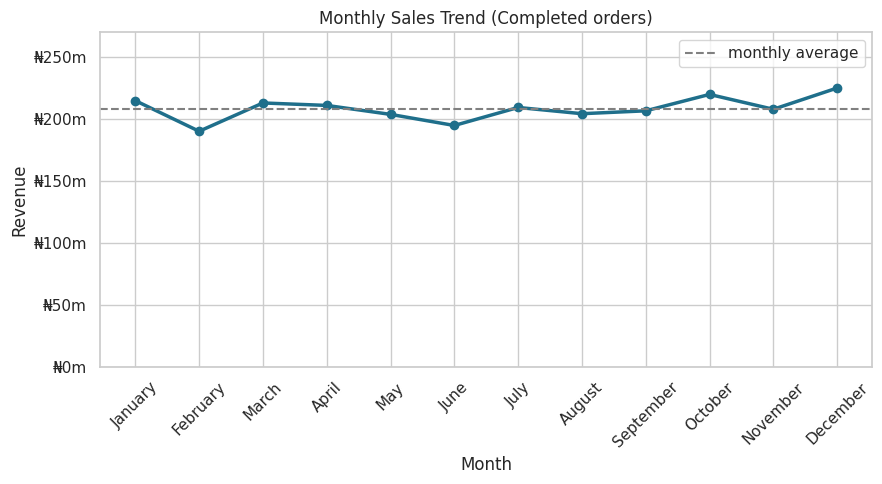

Highest month: December (224,707,991); lowest month: February (189,830,041).
February is short (28 days). Per day, the best month is 11.8% above the worst: sales are fairly flat through the year.


In [25]:
# Chart 1 – Monthly sales trend
monthly = completed_df.groupby('order_month', observed=True)['line_total'].sum()

plt.figure(figsize=(9, 5))
plt.plot(monthly.index.astype(str), monthly.values, marker='o', color=COLOUR, linewidth=2.5)
plt.axhline(monthly.mean(), linestyle='--', color='grey', label='monthly average')
plt.ylim(0, monthly.max() * 1.2)                      # start the axis at zero so small changes are not exaggerated
plt.gca().yaxis.set_major_formatter(mtick.FuncFormatter(millions))
plt.xticks(rotation=45)
plt.title('Monthly Sales Trend (Completed orders)')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.legend()
save_chart('01_monthly_sales_trend.png')
per_day = monthly / monthly.index.map(lambda m: calendar.monthrange(2025, month_names.index(m) + 1)[1]).to_numpy()   # revenue per calendar day in each month
print(f'Highest month: {monthly.idxmax()} ({monthly.max():,.0f}); lowest month: {monthly.idxmin()} ({monthly.min():,.0f}).')
print(f'February is short (28 days). Per day, the best month is {(per_day.max() / per_day.min() - 1) * 100:.1f}% above the worst: sales are fairly flat through the year.')

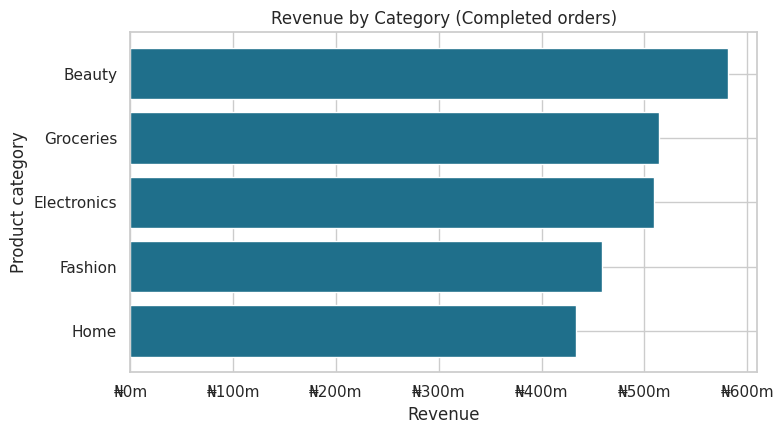

Number of products in each category: {'Beauty': 119, 'Groceries': 102, 'Electronics': 99, 'Fashion': 94, 'Home': 86}


In [26]:
# Chart 2 – Revenue by category
revenue_by_category = completed_df.groupby('category', observed=True)['line_total'].sum().sort_values()

plt.figure(figsize=(8, 4.5))
plt.barh(revenue_by_category.index.astype(str), revenue_by_category.values, color=COLOUR)
plt.gca().xaxis.set_major_formatter(mtick.FuncFormatter(millions))
plt.title('Revenue by Category (Completed orders)')
plt.xlabel('Revenue')
plt.ylabel('Product category')
save_chart('02_revenue_by_category.png')
products_per_category = products_df['category'].value_counts()
print('Number of products in each category:', products_per_category.to_dict())

Beauty earns the most, but it also has the most products (119). Revenue **per product** is very similar across categories.

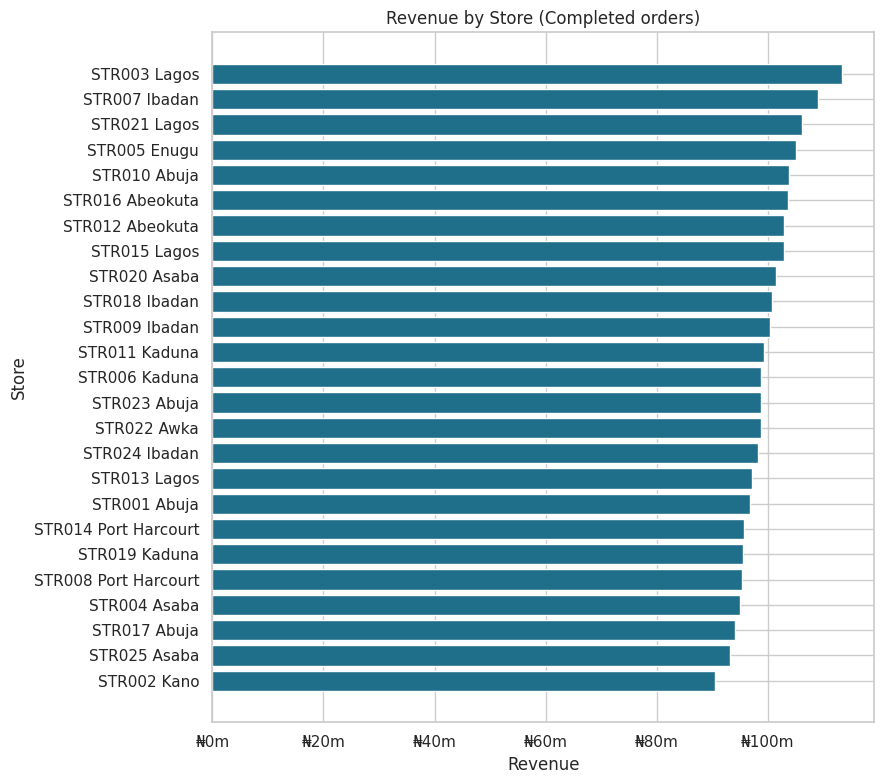

Completed orders: best store STR003 Lagos, weakest STR002 Kano; best is 25.5% above the weakest.
All orders:       best store STR015 Lagos, weakest STR023 Abuja; best is 6.0% above the weakest.
The ranking changes when we change which orders we count. That is a warning sign: the stores are very similar and the gaps are partly luck.


In [27]:
# Chart 3 – Revenue by store (grouped by store_id / store_label, NOT store_name, because several stores share a name)
revenue_by_store = completed_df.groupby('store_label')['line_total'].sum().sort_values()

plt.figure(figsize=(9, 8))
plt.barh(revenue_by_store.index, revenue_by_store.values, color=COLOUR)
plt.gca().xaxis.set_major_formatter(mtick.FuncFormatter(millions))
plt.title('Revenue by Store (Completed orders)')
plt.xlabel('Revenue')
plt.ylabel('Store')
save_chart('03_revenue_by_store.png')
gap_completed = (revenue_by_store.max() / revenue_by_store.min() - 1) * 100
revenue_by_store_all = sales_df.groupby('store_label')['line_total'].sum().sort_values()
gap_all = (revenue_by_store_all.max() / revenue_by_store_all.min() - 1) * 100
print(f'Completed orders: best store {revenue_by_store.idxmax()}, weakest {revenue_by_store.idxmin()}; best is {gap_completed:.1f}% above the weakest.')
print(f'All orders:       best store {revenue_by_store_all.idxmax()}, weakest {revenue_by_store_all.idxmin()}; best is {gap_all:.1f}% above the weakest.')
print('The ranking changes when we change which orders we count. That is a warning sign: the stores are very similar and the gaps are partly luck.')

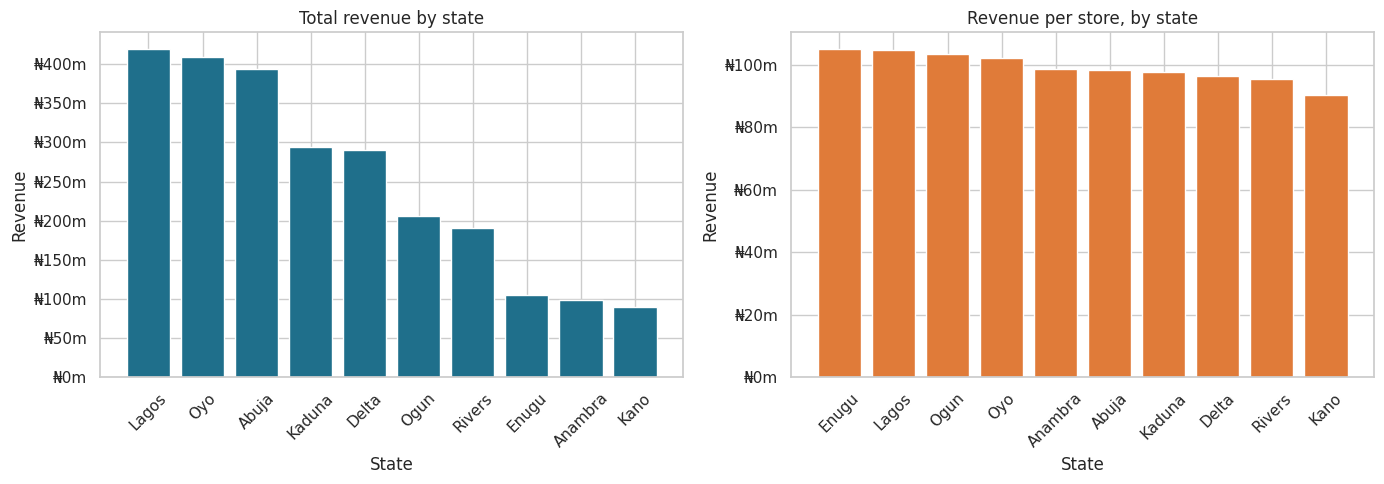

,revenue,stores,revenue_per_store
store_state,,,
Lagos,419568251,4,104892063.0
Oyo,408589880,4,102147470.0
Abuja,393537018,4,98384254.0
Kaduna,293556822,3,97852274.0
Delta,289682630,3,96560877.0
Ogun,206591944,2,103295972.0
Rivers,191058130,2,95529065.0
Enugu,105131425,1,105131425.0
Anambra,98705292,1,98705292.0


States with more stores earn more in total, but per store the states are almost identical.


In [28]:
# Chart 4 – Revenue by state (state of the STORE). Two views: total, and per store (states have different numbers of stores)
by_state = completed_df.groupby('store_state').agg(revenue=('line_total', 'sum'), stores=('store_id', 'nunique'))
by_state['revenue_per_store'] = by_state['revenue'] / by_state['stores']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
a = by_state.sort_values('revenue', ascending=False)
axes[0].bar(a.index, a['revenue'], color=COLOUR)
axes[0].set_title('Total revenue by state')
b = by_state.sort_values('revenue_per_store', ascending=False)
axes[1].bar(b.index, b['revenue_per_store'], color='#e07b39')
axes[1].set_title('Revenue per store, by state')
for ax in axes:
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(millions))
    ax.tick_params(axis='x', rotation=45)
    ax.set_xlabel('State')
    ax.set_ylabel('Revenue')
save_chart('04_revenue_by_state.png')
display(by_state.sort_values('revenue', ascending=False).round(0))
print('States with more stores earn more in total, but per store the states are almost identical.')

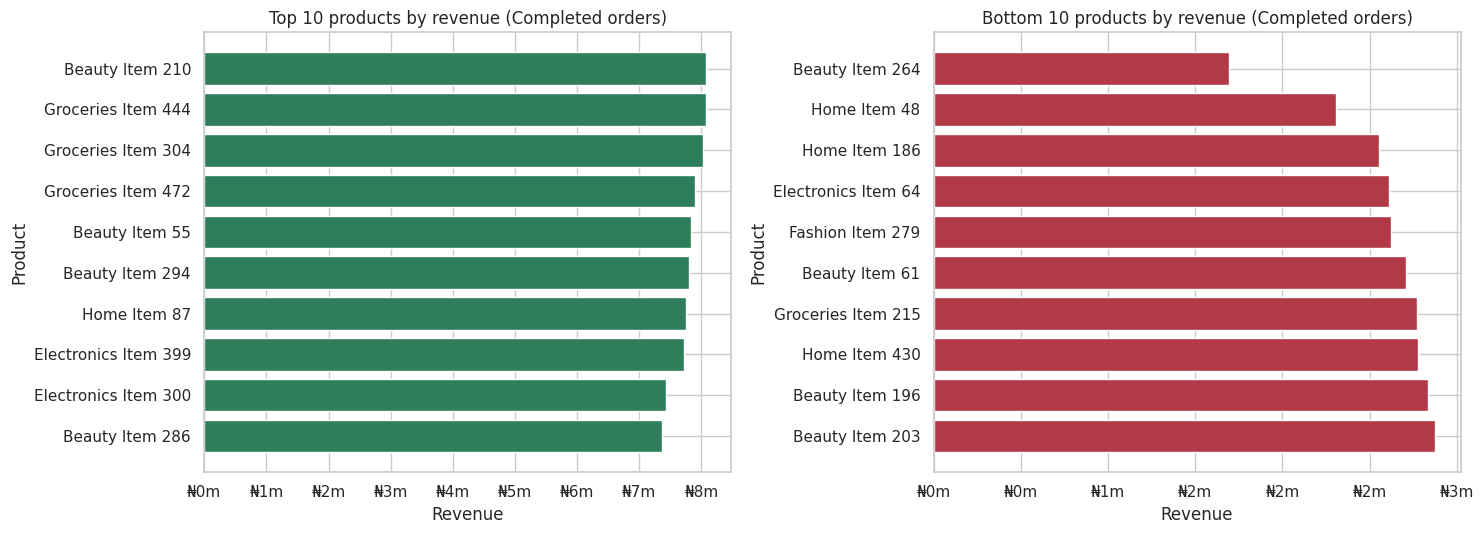

In [29]:
# Charts 5 and 6 – Top 10 and Bottom 10 products
revenue_by_product = completed_df.groupby('product_name')['line_total'].sum()
top_10 = revenue_by_product.nlargest(10).sort_values()
bottom_10 = revenue_by_product.nsmallest(10).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
axes[0].barh(top_10.index, top_10.values, color='#2e7d5b')
axes[0].set_title('Top 10 products by revenue (Completed orders)')
axes[1].barh(bottom_10.index, bottom_10.values, color='#b23a48')
axes[1].set_title('Bottom 10 products by revenue (Completed orders)')
for ax in axes:
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(millions))
    ax.set_xlabel('Revenue')
    ax.set_ylabel('Product')
save_chart('05_06_top_and_bottom_10_products.png')

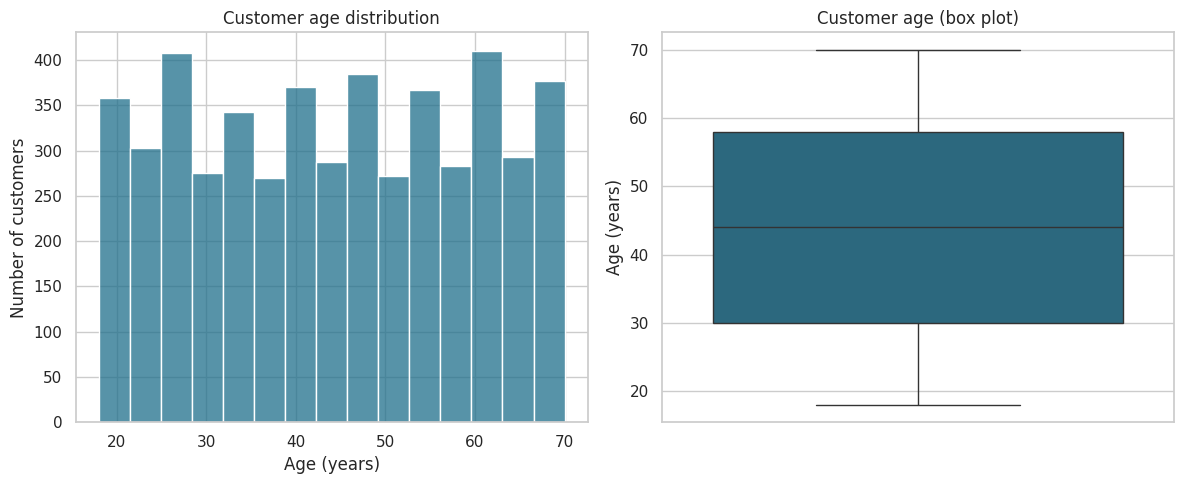

Age: mean 44.2, median 44, youngest 18, oldest 70. Customers are spread evenly from 18 to 70.


In [30]:
# Chart 7 – Customer age distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data=customers_df, x='age', bins=15, color=COLOUR, ax=axes[0])
axes[0].set(title='Customer age distribution', xlabel='Age (years)', ylabel='Number of customers')
sns.boxplot(data=customers_df, y='age', color=COLOUR, ax=axes[1])
axes[1].set(title='Customer age (box plot)', ylabel='Age (years)')
save_chart('07_customer_age_distribution.png')
print(f'Age: mean {customers_df["age"].mean():.1f}, median {customers_df["age"].median():.0f}, youngest {customers_df["age"].min()}, oldest {customers_df["age"].max()}. Customers are spread evenly from 18 to 70.')

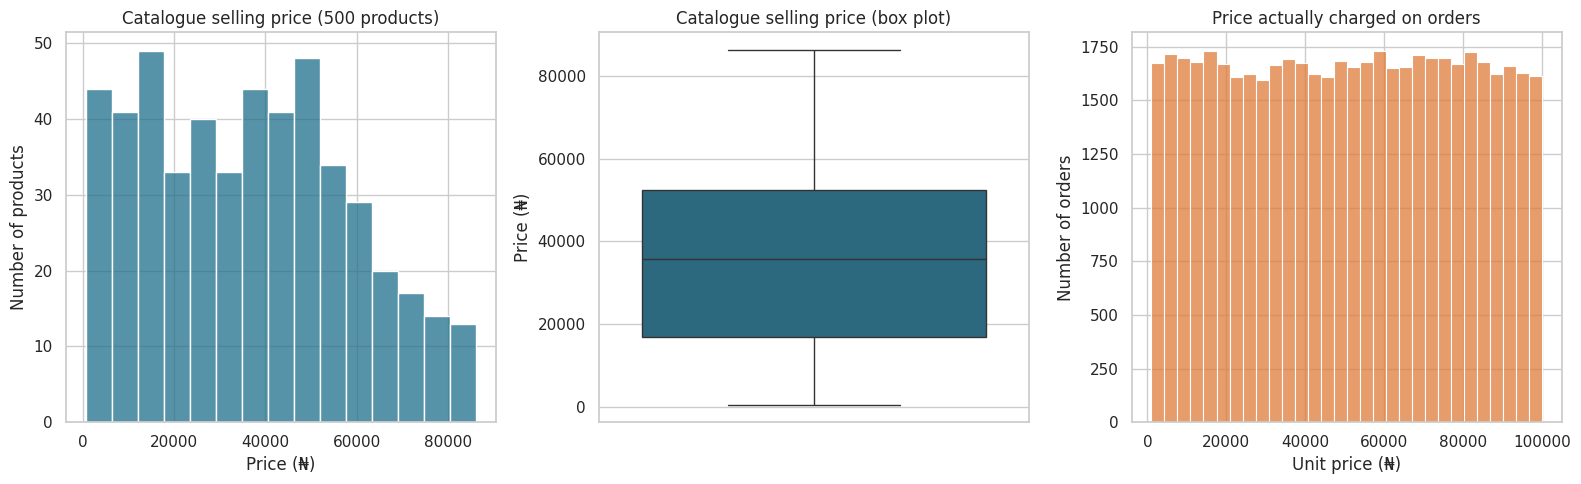

Catalogue prices: ₦676 to ₦86,153. Prices charged: ₦1,003 to ₦99,998.


In [31]:
# Chart 8 – Product price distribution
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
sns.histplot(data=products_df, x='selling_price', bins=15, color=COLOUR, ax=axes[0])
axes[0].set(title='Catalogue selling price (500 products)', xlabel='Price (₦)', ylabel='Number of products')
sns.boxplot(data=products_df, y='selling_price', color=COLOUR, ax=axes[1])
axes[1].set(title='Catalogue selling price (box plot)', ylabel='Price (₦)')
sns.histplot(data=orders_df, x='unit_price', bins=30, color='#e07b39', ax=axes[2])
axes[2].set(title='Price actually charged on orders', xlabel='Unit price (₦)', ylabel='Number of orders')
save_chart('08_product_price_distribution.png')
print(f'Catalogue prices: ₦{products_df["selling_price"].min():,.0f} to ₦{products_df["selling_price"].max():,.0f}. Prices charged: ₦{orders_df["unit_price"].min():,.0f} to ₦{orders_df["unit_price"].max():,.0f}.')

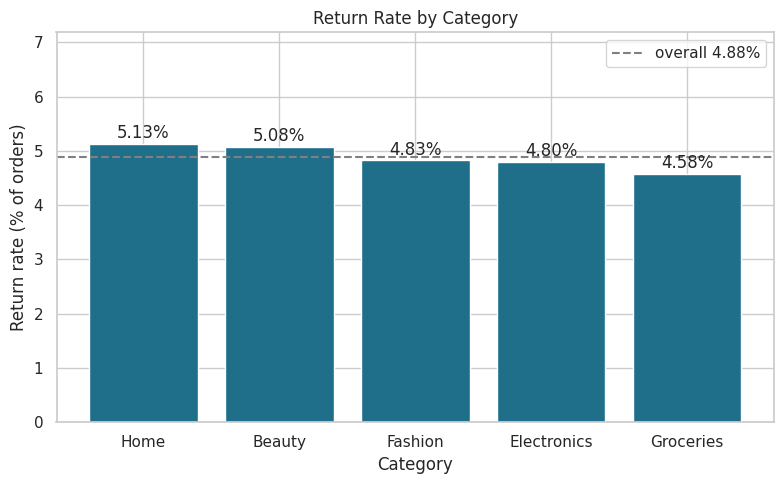

Return rates run from 4.58% to 5.13%: a small spread around the overall rate.


In [32]:
# Chart 9 – Return rate by category (all orders, as in the KPI)
return_rate_by_category = (sales_df.groupby('category', observed=True)['returned'].mean() * 100).sort_values(ascending=False)
overall_return_rate = sales_df['returned'].mean() * 100

plt.figure(figsize=(8, 5))
plt.bar(return_rate_by_category.index.astype(str), return_rate_by_category.values, color=COLOUR)
plt.axhline(overall_return_rate, linestyle='--', color='grey', label=f'overall {overall_return_rate:.2f}%')
plt.ylim(0, return_rate_by_category.max() * 1.4)
for i, v in enumerate(return_rate_by_category.values):
    plt.text(i, v + 0.1, f'{v:.2f}%', ha='center')
plt.title('Return Rate by Category')
plt.xlabel('Category')
plt.ylabel('Return rate (% of orders)')
plt.legend()
save_chart('09_return_rate_by_category.png')
print('Return rates run from', f'{return_rate_by_category.min():.2f}% to {return_rate_by_category.max():.2f}%: a small spread around the overall rate.')

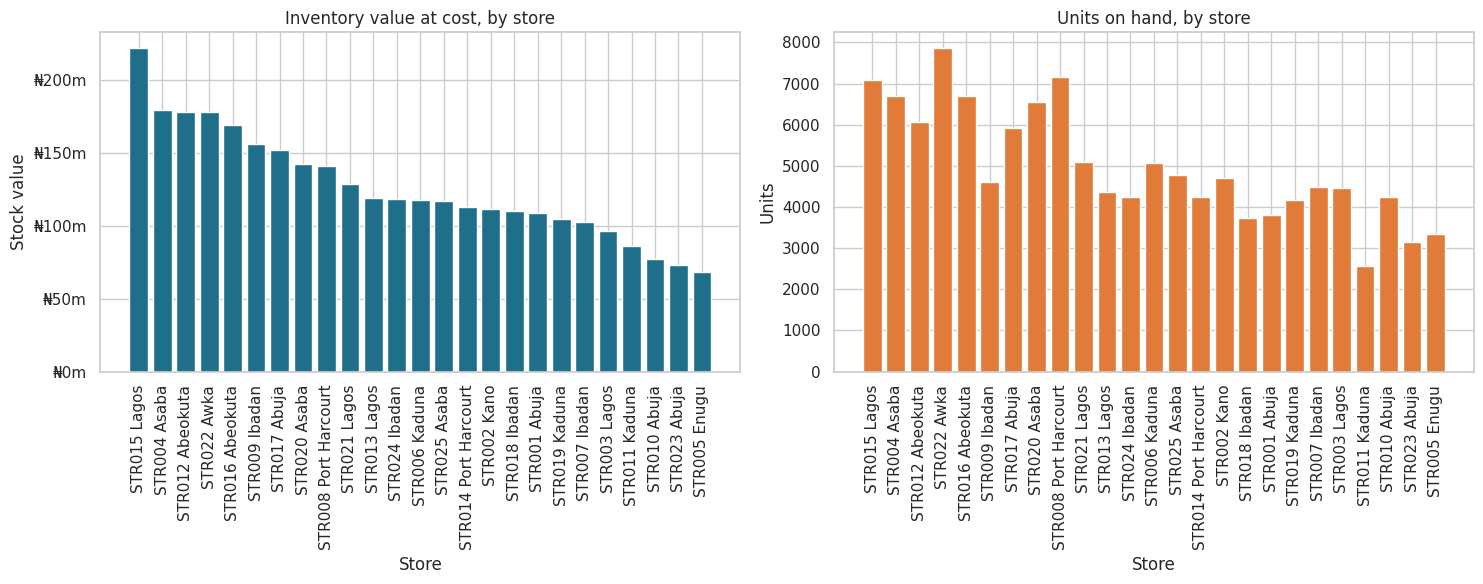

Products held per store range from 9 to 27. Each product is stocked in only ONE store.


In [33]:
# Chart 10 – Inventory by store
# ✅ Fixed: use the inventory table and group by the store that HOLDS the stock (the original grouped by the store that took the order).
inventory_by_store = inventory_analysis_df.groupby('store_label').agg(products=('product_id', 'nunique'), units=('stock_on_hand', 'sum'), value=('stock_value_at_cost', 'sum')).sort_values('value', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].bar(inventory_by_store.index, inventory_by_store['value'], color=COLOUR)
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(millions))
axes[0].set(title='Inventory value at cost, by store', ylabel='Stock value')
axes[1].bar(inventory_by_store.index, inventory_by_store['units'], color='#e07b39')
axes[1].set(title='Units on hand, by store', ylabel='Units')
for ax in axes:
    ax.tick_params(axis='x', rotation=90)
    ax.set_xlabel('Store')
save_chart('10_inventory_by_store.png')
print(f'Products held per store range from {inventory_by_store["products"].min()} to {inventory_by_store["products"].max()}. Each product is stocked in only ONE store.')

---
# Part 6 – Correlation Analysis

A **correlation** (r) measures how two numbers move together: +1 = rise together, −1 = one rises as the other falls, 0 = no linear link. Rough guide: below 0.1 negligible · 0.1–0.3 weak · 0.3–0.5 moderate · above 0.5 strong.



,quantity,unit_price,discount,shipping_cost,line_total,age,selling_price,cost_price
quantity,1.00,0.01,0.01,-0.00,0.60,0.00,0.00,0.00
unit_price,0.01,1.00,-0.01,0.00,0.73,0.01,-0.00,0.00
discount,0.01,-0.01,1.00,-0.00,0.00,0.01,-0.01,-0.01
shipping_cost,-0.00,0.00,-0.00,1.00,0.00,0.01,0.01,0.01
line_total,0.60,0.73,0.00,0.00,1.00,0.01,0.00,0.00
age,0.00,0.01,0.01,0.01,0.01,1.00,-0.01,-0.01
selling_price,0.00,-0.00,-0.01,0.01,0.00,-0.01,1.00,0.96
cost_price,0.00,0.00,-0.01,0.01,0.00,-0.01,0.96,1.00


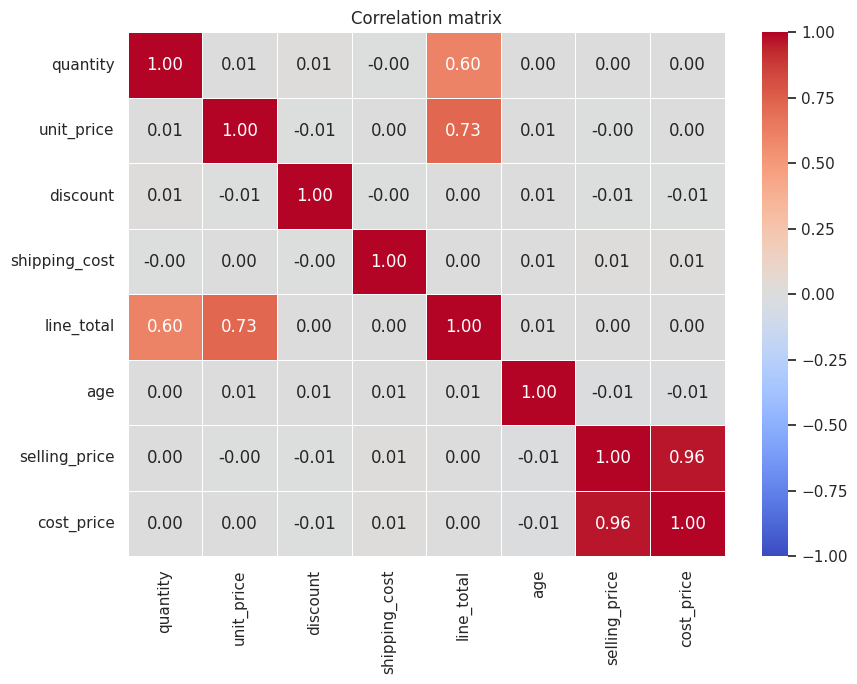

In [34]:
corr_cols = ['quantity', 'unit_price', 'discount', 'shipping_cost', 'line_total', 'age', 'selling_price']
corr_cols = corr_cols + ['cost_price']           # cost_price was added to the orders table in Part 3.6 and carried into sales_df

correlation_matrix = sales_df[corr_cols].corr()
display(correlation_matrix.round(2))

plt.figure(figsize=(9, 7))
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Correlation matrix')
save_chart('11_correlation_heatmap.png')

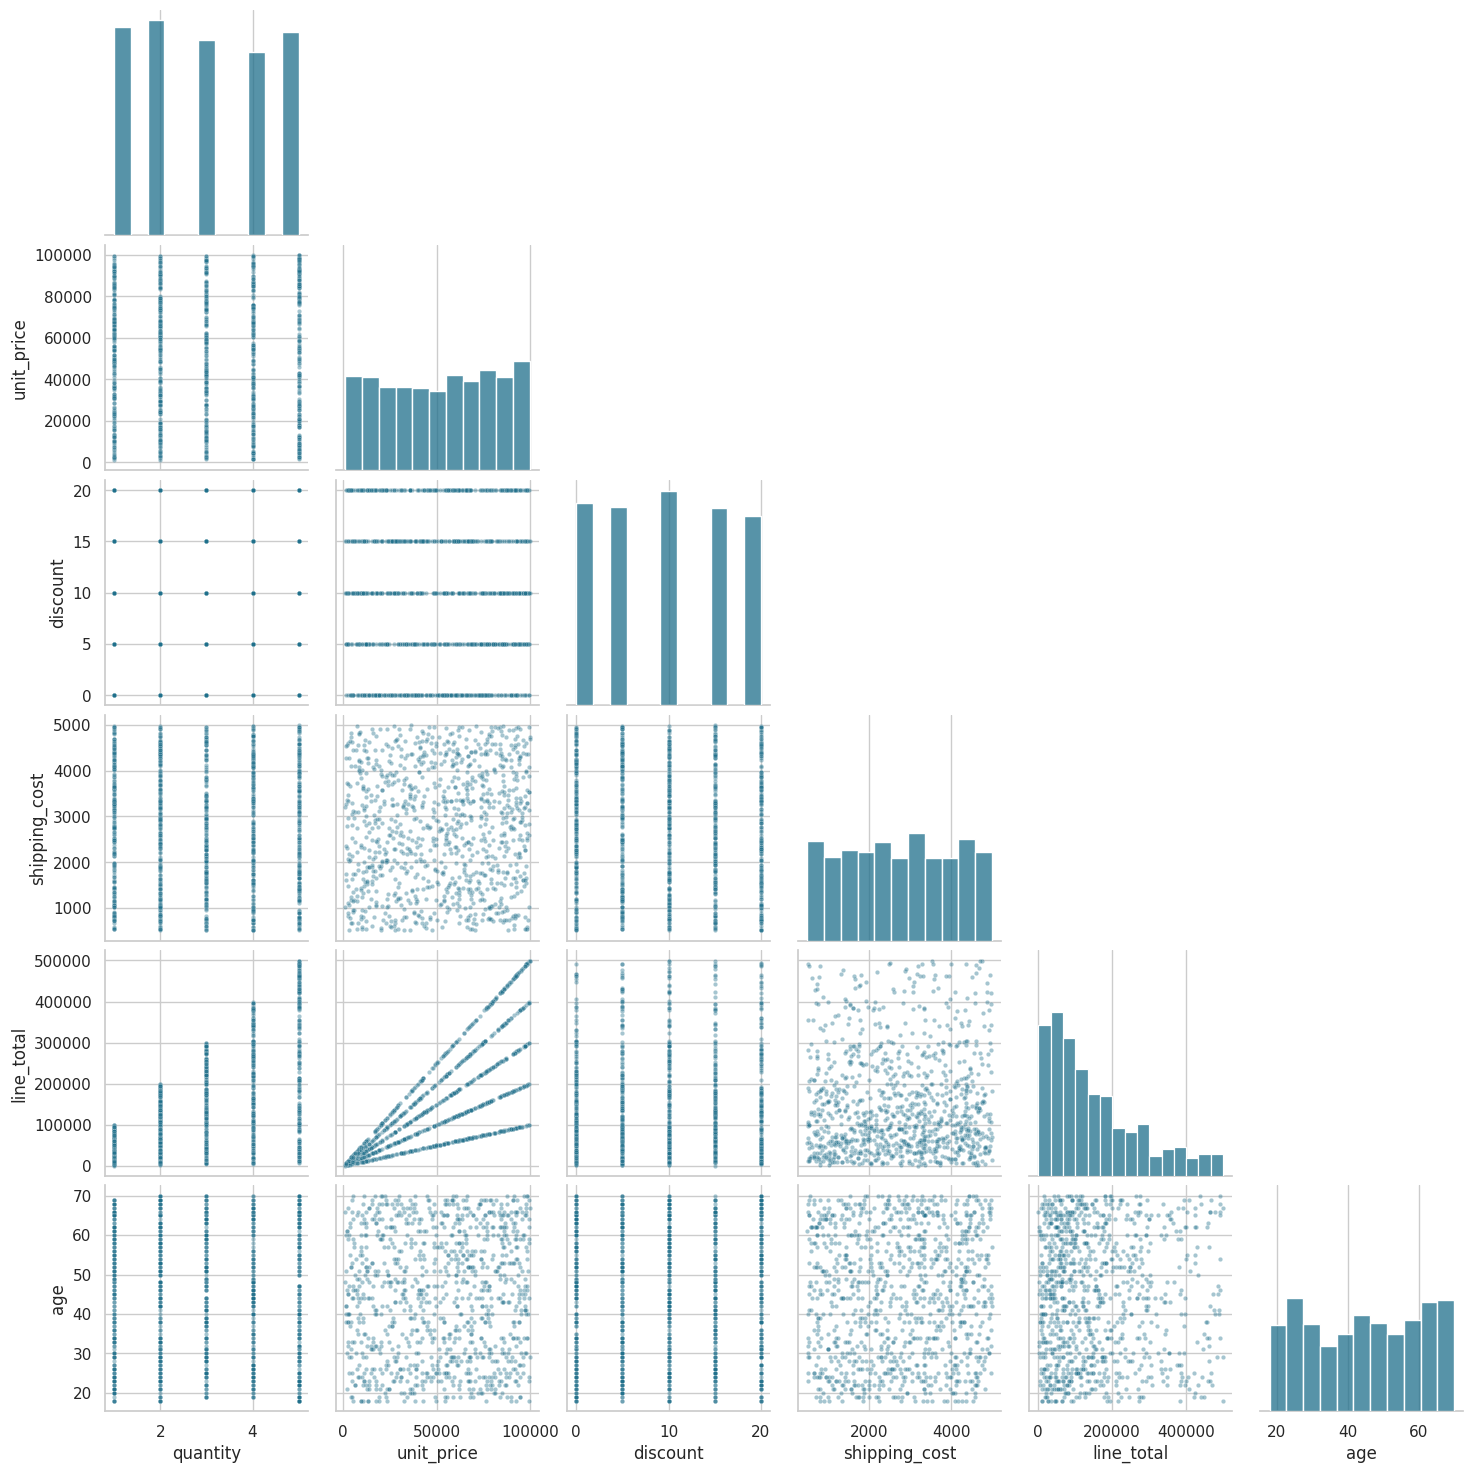

In [35]:
# Pair plot of selected numerical features (1,000 random rows keep it fast and readable)
pair_cols = ['quantity', 'unit_price', 'discount', 'shipping_cost', 'line_total', 'age']
sns.pairplot(sales_df[pair_cols].sample(1000, random_state=42), corner=True, plot_kws={'s': 10, 'alpha': 0.4, 'color': COLOUR}, diag_kws={'color': COLOUR})
plt.savefig('Visualizations/12_pair_plot.png', dpi=130, bbox_inches='tight')
plt.show()

### List the pairs automatically
Instead of reading 28 numbers by eye, turn the matrix into a list of pairs and sort it.

In [36]:
upper = correlation_matrix.where(np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool))      # keep each pair once
pairs = upper.stack().dropna().reset_index()          # dropna removes the empty lower-triangle cells
pairs.columns = ['variable_1', 'variable_2', 'r']
pairs['strength'] = pairs['r'].abs()
pairs = pairs.sort_values('strength', ascending=False)

print('STRONGLY correlated (|r| of 0.5 or more):')
display(pairs[pairs['strength'] >= 0.5].round(2))
print('Practically UNRELATED (|r| below 0.05):', (pairs['strength'] < 0.05).sum(), 'of', len(pairs), 'pairs. Examples:')
display(pairs[pairs['strength'] < 0.05].head(8).round(3))

STRONGLY correlated (|r| of 0.5 or more):


,variable_1,variable_2,r,strength
27,selling_price,cost_price,0.96,0.96
9,unit_price,line_total,0.73,0.73
3,quantity,line_total,0.60,0.60


Practically UNRELATED (|r| below 0.05): 25 of 28 pairs. Examples:


,variable_1,variable_2,r,strength
20,shipping_cost,selling_price,0.011,0.011
21,shipping_cost,cost_price,0.011,0.011
1,quantity,discount,0.008,0.008
25,age,selling_price,-0.008,0.008
26,age,cost_price,-0.008,0.008
0,quantity,unit_price,0.008,0.008
10,unit_price,age,0.007,0.007
22,line_total,age,0.007,0.007


### Explanation (what the brief asks)

**1. Which variables are strongly correlated?**
* `line_total` with `unit_price` (about 0.73) and with `quantity` (about 0.60). This is *by construction*: `line_total = quantity × unit_price − discount`. It tells us about the formula, not about customer behaviour.
* `cost_price` with `selling_price` (about 0.96). The price list was made by adding a mark-up to cost, so products that cost more are priced higher. This one is a genuine business rule.

**2. Which variables appear unrelated?**
* `age`, `shipping_cost` and `discount` have almost no correlation with anything (all below 0.05). Older customers do not spend more, bigger discounts do not increase quantity, and shipping cost is unrelated to order size.
* `unit_price` (the price charged) is unrelated to `selling_price` (the catalogue price). That is surprising: the price charged should be close to the price list.

**3. How could these relationships be useful?**
* The mark-up pattern (`cost` → `selling_price`) can be used to check prices: an order priced far from its product's usual price needs investigating (we found many sold below cost).
* Because `line_total` is calculated from `quantity` and `unit_price`, never use one to "predict" the other in a model; it would look perfect but teach nothing.
* No correlation between `discount` and `quantity` suggests discounts are not increasing sales volume, which management should test.
* The lack of relationships means that these columns cannot predict customer behaviour; a machine learning model will need richer data (for example delivery time, product ratings, browsing history).

---
# Part 7 – Feature Engineering

New columns that may help future models. Each is created on the correct table and the reason it helps is listed at the end.

### 7.1 Order-level features: profit margin, order month, quarter, discount percentage

In [37]:
# Profit margin 
# profit margin (%) = (revenue - cost of goods sold) / revenue x 100
sales_df['cogs'] = sales_df['quantity'] * sales_df['cost_price']               # cost of goods sold for the order
sales_df['gross_profit'] = sales_df['line_total'] - sales_df['cogs']
sales_df['profit_margin'] = (sales_df['gross_profit'] / sales_df['line_total']) * 100

# Time features
sales_df['order_quarter'] = 'Q' + sales_df['order_date'].dt.quarter.astype(str)
# (order_month was already created in Part 4)

# Discount percentage 
sales_df['discount_pct'] = sales_df['discount']                                                       # treating the 0-20 values as percentages
sales_df['discount_pct_of_value'] = sales_df['discount'] / (sales_df['quantity'] * sales_df['unit_price']) * 100   # what the recorded amount really is, as a % of the order

display(sales_df[['order_id', 'line_total', 'cogs', 'gross_profit', 'profit_margin', 'order_month', 'order_quarter', 'discount_pct', 'discount_pct_of_value']].head())
print(f'Median profit margin: {sales_df["profit_margin"].median():.1f}%  |  mean: {sales_df["profit_margin"].mean():.1f}% (pulled down by a few very large losses)  |  orders with a negative margin: {(sales_df["profit_margin"] < 0).mean():.1%}')
print(f'If discount is a flat naira amount, it is on average only {sales_df["discount_pct_of_value"].mean():.3f}% of the order value.')

,order_id,line_total,cogs,gross_profit,profit_margin,order_month,order_quarter,discount_pct,discount_pct_of_value
0,ORD000001,77979,48631,29348,37.635774,July,Q3,10,0.012822
1,ORD000002,33715,9807,23908,70.912057,March,Q1,5,0.014828
2,ORD000003,47170,62054,-14884,-31.553954,October,Q4,20,0.042382
3,ORD000004,279683,116856,162827,58.218412,July,Q3,5,0.001788
4,ORD000005,266720,176120,90600,33.968206,March,Q1,0,0.000000


Median profit margin: 50.3%  |  mean: -18.6% (pulled down by a few very large losses)  |  orders with a negative margin: 24.3%
If discount is a flat naira amount, it is on average only 0.021% of the order value.


### 7.2 Customer age group


In [38]:
age_bins = [17, 24, 34, 44, 54, 64, 100]
age_labels = ['18-24', '25-34', '35-44', '45-54', '55-64', '65+']
customers_df['age_group'] = pd.cut(customers_df['age'], bins=age_bins, labels=age_labels)
sales_df['age_group'] = pd.cut(sales_df['age'], bins=age_bins, labels=age_labels)
print(customers_df['age_group'].value_counts().sort_index())

age_group
18-24    661
25-34    939
35-44    928
45-54    924
55-64    986
65+      562
Name: count, dtype: int64


### 7.3 Customer-level features: days since last purchase and customer lifetime value (CLV)
These must be calculated **per customer** (one row per customer), not per order.


In [39]:
reference_date = sales_df['order_date'].max() + pd.Timedelta(days=1)       # fixed date so the result never changes
print('Reference date:', reference_date.date())

completed_df = sales_df[sales_df['order_status'] == 'Completed'].copy()    # rebuild so it includes the new columns

customer_features = completed_df.groupby('customer_id').agg(
    completed_orders=('order_id', 'count'),
    total_revenue=('line_total', 'sum'),
    total_gross_profit=('gross_profit', 'sum'),
    last_purchase=('order_date', 'max'),
).reset_index()

customer_features['days_since_last_purchase'] = (reference_date - customer_features['last_purchase']).dt.days
customer_features['avg_order_value'] = customer_features['total_revenue'] / customer_features['completed_orders']

# CLV approximation = profit made in the year x number of years we assume the customer stays
customer_features['clv_approx'] = customer_features['total_gross_profit'] * LIFESPAN_YEARS
customer_features = customer_features.merge(customers_df[['customer_id', 'age', 'age_group', 'customer_segment']], on='customer_id', how='left')

print(f'{len(customer_features):,} of {len(customers_df):,} customers have at least one Completed order.')
display(customer_features[['days_since_last_purchase', 'avg_order_value', 'total_gross_profit', 'clv_approx']].describe().round(0))

Reference date: 2026-01-01
4,795 of 5,000 customers have at least one Completed order.


,days_since_last_purchase,avg_order_value,total_gross_profit,clv_approx
count,4795.0,4795.0,4795.0,4795.0
mean,97.0,150771.0,261540.0,784620.0
std,84.0,75058.0,249988.0,749963.0
min,1.0,1590.0,-381959.0,-1145877.0
25%,30.0,97829.0,76506.0,229520.0
50%,71.0,143139.0,218146.0,654438.0
75%,141.0,193416.0,403770.0,1211310.0
max,364.0,494775.0,1527705.0,4583115.0


CLV here is an **approximation**: it assumes each customer keeps buying at this year's rate for 3 years (`LIFESPAN_YEARS`, an assumption). Use it to *rank* customers, not as a promise of future money.

### 7.4 Inventory status (Low / Medium / High)
Raw stock numbers can mislead: 100 units is plenty for a slow product and nothing for a fast one. So I compare stock with how fast the product sells (**days of cover** = stock ÷ units sold per day).

* **Low** – stock is at or below the reorder level, *or* it will last less than 30 days → restock
* **High** – it will last more than a year → overstocked
* **Medium** – everything else


In [40]:
units_per_product = sales_df[sales_df['order_status'] != 'Cancelled'].groupby('product_id')['quantity'].sum()     # cancelled orders never use stock
days_in_data = (sales_df['order_date'].max() - sales_df['order_date'].min()).days + 1

inventory_analysis_df['units_sold'] = inventory_analysis_df['product_id'].map(units_per_product)
inventory_analysis_df['daily_demand'] = inventory_analysis_df['units_sold'] / days_in_data
inventory_analysis_df['days_of_cover'] = inventory_analysis_df['stock_on_hand'] / inventory_analysis_df['daily_demand']

low_rule  = (inventory_analysis_df['stock_on_hand'] <= inventory_analysis_df['reorder_level']) | (inventory_analysis_df['days_of_cover'] < 30)
high_rule = inventory_analysis_df['days_of_cover'] > 365
inventory_analysis_df['inventory_status'] = np.select([low_rule, high_rule], ['Low', 'High'], default='Medium')

status_counts = inventory_analysis_df['inventory_status'].value_counts().reindex(['Low', 'Medium', 'High'])
display(status_counts.to_frame('products'))
print('Stock value of High-status products:', f'{inventory_analysis_df.loc[inventory_analysis_df["inventory_status"] == "High", "stock_value_at_cost"].sum():,.0f}',
      'out of a total of', f'{inventory_analysis_df["stock_value_at_cost"].sum():,.0f}')

,products
inventory_status,
Low,23
Medium,170
High,307


Stock value of High-status products: 2,716,869,461 out of a total of 3,169,020,818


### 7.5 Why each feature may improve a future model

| Feature | Why it may help |
|---|---|
| `profit_margin` | Shows how profitable an order is regardless of its size; useful for pricing and profitability models |
| `order_month`, `order_quarter` | Let a model learn seasonal patterns (for sales forecasting and stock planning) |
| `age_group` | Groups ages into life stages, which models and marketing teams use more easily than raw ages |
| `clv_approx` | Ranks customers by value, so retention effort can focus on the most valuable |
| `discount_pct` | Measures how much price was given away; needed to study whether discounts work |
| `days_since_last_purchase` | Recency is one of the best signals that a customer is about to stop buying (churn) |
| `inventory_status` / `days_of_cover` | Turn stock numbers into an action (restock or not); base for stock-out prediction |

In [41]:
# Save the feature tables
sales_df.to_csv('Cleaned_Data/sales_features.csv', index=False)
customer_features.to_csv('Cleaned_Data/customer_features.csv', index=False)
inventory_analysis_df.to_csv('Cleaned_Data/inventory_features.csv', index=False)
print('Saved: sales_features.csv, customer_features.csv, inventory_features.csv')

Saved: sales_features.csv, customer_features.csv, inventory_features.csv


---
# Part 8 – Business Questions
Revenue questions use `completed_df` (Completed orders). Return questions use all orders (as in the KPI). Each answer is printed by the code from the results.

**A rule for every "which is best / worst" question:** always check *how big* the gap is. In this dataset many gaps are small, so naming a "winner" without saying how close the others are would mislead management.

## Q1. Which products generate the most revenue?

In [42]:
product_revenue = completed_df.groupby(['product_name', 'category'])['line_total'].sum().sort_values(ascending=False).reset_index()
product_revenue['share_of_revenue_%'] = product_revenue['line_total'] / product_revenue['line_total'].sum() * 100
display(product_revenue.head(10).style.format({'line_total': '{:,.0f}', 'share_of_revenue_%': '{:.2f}%'}))

top10_share = product_revenue['share_of_revenue_%'].head(10).sum()
ratio = product_revenue['line_total'].iloc[0] / product_revenue['line_total'].median()
print(f"ANSWER: The top product is {product_revenue.iloc[0]['product_name']} ({product_revenue.iloc[0]['line_total']:,.0f}), followed by "
      f"{product_revenue.iloc[1]['product_name']} and {product_revenue.iloc[2]['product_name']}. The top 10 products together give {top10_share:.1f}% of revenue "
      f"(if all 500 were equal it would be 2%). The best product earns only {ratio:.1f} times the typical (median) product, so revenue is spread very evenly.")

top10_all_orders = set(sales_df.groupby('product_name')['line_total'].sum().nlargest(10).index)
overlap = len(top10_all_orders & set(product_revenue['product_name'].head(10)))
print(f"NOTE: Only {overlap} of these 10 products are also in the top 10 when ALL orders are counted. The 'top' products change with the base used, another sign that product revenues are very close.")

,product_name,category,line_total,share_of_revenue_%
0,Beauty Item 210,Beauty,"8,075,117",0.32%
1,Groceries Item 444,Groceries,"8,069,660",0.32%
2,Groceries Item 304,Groceries,"8,019,239",0.32%
3,Groceries Item 472,Groceries,"7,896,309",0.32%
4,Beauty Item 55,Beauty,"7,828,172",0.31%
5,Beauty Item 294,Beauty,"7,801,631",0.31%
6,Home Item 87,Home,"7,747,021",0.31%
7,Electronics Item 399,Electronics,"7,719,854",0.31%
8,Electronics Item 300,Electronics,"7,430,303",0.30%
9,Beauty Item 286,Beauty,"7,369,809",0.30%


ANSWER: The top product is Beauty Item 210 (8,075,117), followed by Groceries Item 444 and Groceries Item 304. The top 10 products together give 3.1% of revenue (if all 500 were equal it would be 2%). The best product earns only 1.6 times the typical (median) product, so revenue is spread very evenly.
NOTE: Only 1 of these 10 products are also in the top 10 when ALL orders are counted. The 'top' products change with the base used, another sign that product revenues are very close.


## Q2. Which stores perform best?

In [43]:
store_table = completed_df.groupby('store_label').agg(revenue=('line_total', 'sum'), completed_orders=('order_id', 'count'), avg_order_value=('line_total', 'mean')).sort_values('revenue', ascending=False)
store_table['vs_average_%'] = (store_table['revenue'] / store_table['revenue'].mean() - 1) * 100
display(pd.concat([store_table.head(5), store_table.tail(3)]).style.format({'revenue': '{:,.0f}', 'avg_order_value': '{:,.0f}', 'vs_average_%': '{:+.1f}%'}))

print(f"ANSWER: On Completed orders the best stores are {', '.join(store_table.index[:3])}. The best store is {store_table['vs_average_%'].iloc[0]:+.1f}% vs the average store and the weakest "
      f"({store_table.index[-1]}) is {store_table['vs_average_%'].iloc[-1]:+.1f}%. The number of completed orders (about {store_table['completed_orders'].mean():.0f} per store) explains most of the difference, not order size. "
      f"Caution: on ALL orders the best store is {revenue_by_store_all.idxmax()} and the gap is only {gap_all:.1f}%, so no store is clearly better than the others.")

,revenue,completed_orders,avg_order_value,vs_average_%
store_label,,,,
STR003 Lagos,"113,445,250",715,"158,665",+13.6%
STR007 Ibadan,"109,092,311",668,"163,312",+9.2%
STR021 Lagos,"106,157,614",699,"151,871",+6.3%
STR005 Enugu,"105,131,425",681,"154,378",+5.3%
STR010 Abuja,"103,831,604",680,"152,694",+4.0%
STR017 Abuja,"94,132,850",623,"151,096",-5.7%
STR025 Asaba,"93,212,609",641,"145,417",-6.7%
STR002 Kano,"90,402,991",632,"143,043",-9.5%


ANSWER: On Completed orders the best stores are STR003 Lagos, STR007 Ibadan, STR021 Lagos. The best store is +13.6% vs the average store and the weakest (STR002 Kano) is -9.5%. The number of completed orders (about 661 per store) explains most of the difference, not order size. Caution: on ALL orders the best store is STR015 Lagos and the gap is only 6.0%, so no store is clearly better than the others.


## Q3. Which customer segments spend the most?
Compare **spend per customer** (revenue ÷ number of customers in the group) so bigger groups do not look better just because they are bigger.

,customers,revenue,revenue_per_customer
customer_segment,,,
Bronze,1635,"815,481,758","498,766"
Silver,1674,"833,131,549","497,689"
Gold,1691,"848,211,076","501,603"


,customers,revenue,revenue_per_customer
age_group,,,
18-24,661,"329,579,502","498,607"
25-34,939,"473,772,424","504,550"
35-44,928,"470,155,745","506,633"
45-54,924,"465,794,182","504,106"
55-64,986,"488,056,714","494,987"
65+,562,"269,465,816","479,477"


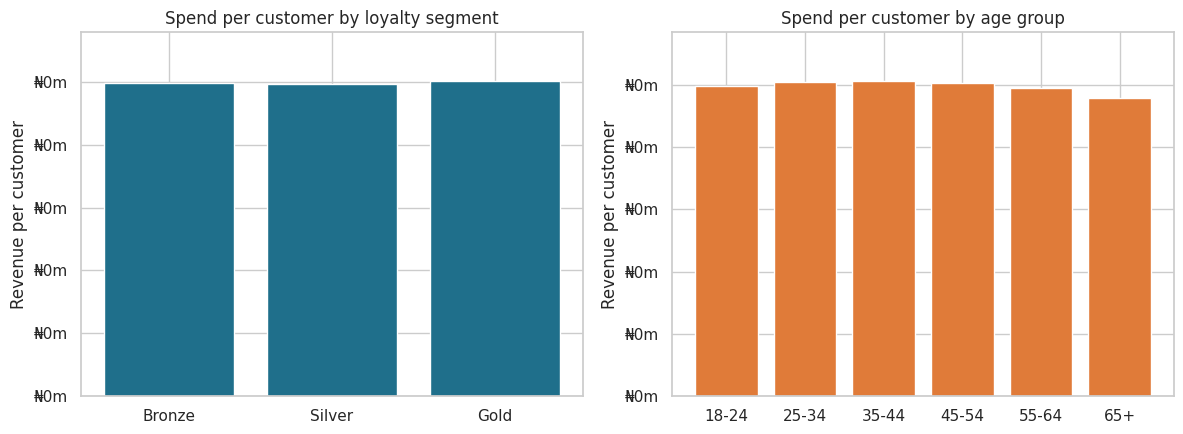

ANSWER: Gold customers spend the most per customer, but the gap between the best and worst loyalty segment is only 0.8% (age groups: 5.7%). The Gold tier does not spend noticeably more than Bronze. The real differences are between individual customers: the top 10% of customers give 23.9% of revenue.


In [44]:
def spend_by_group(group_col):
    revenue = completed_df.groupby(group_col, observed=True)['line_total'].sum()
    customers = customers_df.groupby(group_col, observed=True)['customer_id'].count()
    table = pd.DataFrame({'customers': customers, 'revenue': revenue})
    table['revenue_per_customer'] = table['revenue'] / table['customers']
    return table

by_segment = spend_by_group('customer_segment')
by_age = spend_by_group('age_group')
display(by_segment.style.format({'revenue': '{:,.0f}', 'revenue_per_customer': '{:,.0f}'}))
display(by_age.style.format({'revenue': '{:,.0f}', 'revenue_per_customer': '{:,.0f}'}))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(by_segment.index.astype(str), by_segment['revenue_per_customer'], color=COLOUR)
axes[0].set(title='Spend per customer by loyalty segment', ylabel='Revenue per customer')
axes[1].bar(by_age.index.astype(str), by_age['revenue_per_customer'], color='#e07b39')
axes[1].set(title='Spend per customer by age group', ylabel='Revenue per customer')
for ax in axes:
    ax.set_ylim(0, ax.get_ylim()[1] * 1.1)
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(millions))
save_chart('13_customer_spend_by_group.png')

seg_gap = (by_segment['revenue_per_customer'].max() / by_segment['revenue_per_customer'].min() - 1) * 100
age_gap = (by_age['revenue_per_customer'].max() / by_age['revenue_per_customer'].min() - 1) * 100
top_cust = customer_features.sort_values('total_revenue', ascending=False)
top10pct_share = top_cust['total_revenue'].head(len(top_cust) // 10).sum() / top_cust['total_revenue'].sum() * 100
print(f"ANSWER: {by_segment['revenue_per_customer'].idxmax()} customers spend the most per customer, but the gap between the best and worst loyalty segment is only {seg_gap:.1f}% "
      f"(age groups: {age_gap:.1f}%). The Gold tier does not spend noticeably more than Bronze. The real differences are between individual customers: the top 10% of customers give {top10pct_share:.1f}% of revenue.")

## Q4. Which products have high return rates?


In [45]:
product_returns = sales_df.groupby('product_name').agg(orders=('order_id', 'count'), returned_orders=('returned', 'sum'))
product_returns['return_rate_%'] = product_returns['returned_orders'] / product_returns['orders'] * 100
display(product_returns.sort_values('return_rate_%', ascending=False).head(10).style.format({'return_rate_%': '{:.1f}%'}))

avg_orders = product_returns['orders'].mean()
print(f"ANSWER: The highest return rates are {', '.join(product_returns.sort_values('return_rate_%', ascending=False).index[:3])} "
      f"(up to {product_returns['return_rate_%'].max():.1f}%) against an overall rate of {overall_return_rate:.2f}%. But each product has only about {avg_orders:.0f} orders, "
      f"so 5 returns is a {5 / avg_orders * 100:.0f}% rate and 9 returns is {9 / avg_orders * 100:.0f}%: a difference of a few returns is normal luck. "
      f"By category the rates are all close ({return_rate_by_category.min():.2f}% to {return_rate_by_category.max():.2f}%). No product is clearly a problem.")

,orders,returned_orders,return_rate_%
product_name,,,
Home Item 263,95,11,11.6%
Beauty Item 262,88,10,11.4%
Beauty Item 443,92,10,10.9%
Fashion Item 349,94,10,10.6%
Home Item 5,96,10,10.4%
Beauty Item 191,89,9,10.1%
Home Item 142,91,9,9.9%
Beauty Item 271,92,9,9.8%
Beauty Item 6,73,7,9.6%


ANSWER: The highest return rates are Home Item 263, Beauty Item 262, Beauty Item 443 (up to 11.6%) against an overall rate of 4.88%. But each product has only about 100 orders, so 5 returns is a 5% rate and 9 returns is 9%: a difference of a few returns is normal luck. By category the rates are all close (4.58% to 5.13%). No product is clearly a problem.


## Q5. Which months have peak sales?

In [46]:
month_table = completed_df.groupby('order_month', observed=True).agg(revenue=('line_total', 'sum'))
month_table['days'] = [calendar.monthrange(2025, i + 1)[1] for i in range(12)]
month_table['revenue_per_day'] = month_table['revenue'] / month_table['days']
display(month_table.sort_values('revenue', ascending=False).style.format({'revenue': '{:,.0f}', 'revenue_per_day': '{:,.0f}'}))

best3 = month_table.sort_values('revenue', ascending=False).head(3).index.astype(str).tolist()
print(f"ANSWER: The highest-revenue months are {', '.join(best3)}; the lowest is {month_table['revenue'].idxmin()}, partly because it has fewer days. "
      f"Per day, the best month ({month_table['revenue_per_day'].idxmax()}) is {(month_table['revenue_per_day'].max() / month_table['revenue_per_day'].min() - 1) * 100:.1f}% above the worst. "
      f"There is no strong seasonal peak in 2025.")

,revenue,days,revenue_per_day
order_month,,,
December,"224,707,991",31,"7,248,645"
October,"219,554,180",31,"7,082,393"
January,"214,519,557",31,"6,919,986"
March,"212,666,807",31,"6,860,220"
April,"210,682,482",30,"7,022,749"
July,"209,026,574",31,"6,742,793"
November,"207,572,239",30,"6,919,075"
September,"206,323,482",30,"6,877,449"
August,"204,002,747",31,"6,580,734"


ANSWER: The highest-revenue months are December, October, January; the lowest is February, partly because it has fewer days. Per day, the best month (December) is 11.8% above the worst. There is no strong seasonal peak in 2025.


## Q6. Which categories are growing?


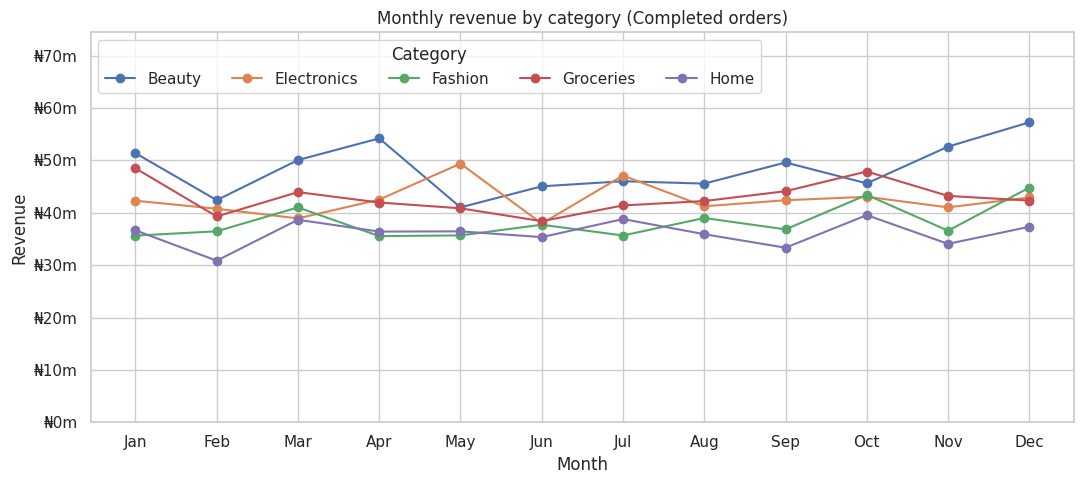

,Jul-Dec vs Jan-Jun (%),typical month-to-month swing (%)
category,,
Beauty,4.4,11.1
Electronics,2.3,9.7
Fashion,6.4,10.1
Groceries,3.3,7.1
Home,2.1,10.6


ANSWER: Comparing July-December with January-June, Fashion grew most (+6.4%) and Home changed least (+2.1%). But revenue normally swings by about 10% from one month to the next, so these changes are within normal ups and downs. With only one year of data we cannot say any category is truly growing.


In [47]:
category_month = completed_df.groupby(['order_month', 'category'], observed=True)['line_total'].sum().unstack()

category_month.plot(figsize=(11, 5), marker='o')
plt.ylim(0, category_month.max().max() * 1.3)
plt.gca().yaxis.set_major_formatter(mtick.FuncFormatter(millions))
plt.title('Monthly revenue by category (Completed orders)')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.xticks(range(12), [m[:3] for m in month_names])
plt.legend(title='Category', loc='upper left', ncol=5)
save_chart('14_category_revenue_by_month.png')

first_half, second_half = category_month.iloc[:6].sum(), category_month.iloc[6:].sum()
growth = ((second_half / first_half - 1) * 100).sort_values(ascending=False).round(1)
month_to_month = (category_month.pct_change().abs().mean() * 100).round(1)
display(pd.DataFrame({'Jul-Dec vs Jan-Jun (%)': growth, 'typical month-to-month swing (%)': month_to_month}))
print(f"ANSWER: Comparing July-December with January-June, {growth.index[0]} grew most ({growth.iloc[0]:+.1f}%) and {growth.index[-1]} changed least ({growth.iloc[-1]:+.1f}%). "
      f"But revenue normally swings by about {month_to_month.mean():.0f}% from one month to the next, so these changes are within normal ups and downs. "
      f"With only one year of data we cannot say any category is truly growing.")

## Q7. Which suppliers perform best?


In [48]:
supplier_sales = sales_df.merge(suppliers_df[['supplier_id', 'supplier_name', 'supplier_brand', 'supplier_country']], left_on='brand', right_on='supplier_brand', how='left')
assert len(supplier_sales) == len(sales_df) and supplier_sales['supplier_id'].notna().all()           # every order found its supplier, no rows added

supplier_sales['completed_revenue'] = supplier_sales['line_total'].where(supplier_sales['order_status'] == 'Completed', 0)
supplier_sales['completed_profit'] = supplier_sales['gross_profit'].where(supplier_sales['order_status'] == 'Completed', 0)

supplier_table = supplier_sales.groupby(['supplier_name', 'supplier_country']).agg(
    revenue=('completed_revenue', 'sum'), profit=('completed_profit', 'sum'), orders=('order_id', 'count'), returned=('returned', 'sum')).reset_index()
supplier_table['margin_%'] = supplier_table['profit'] / supplier_table['revenue'] * 100
supplier_table['return_rate_%'] = supplier_table['returned'] / supplier_table['orders'] * 100

# simple score: rank every supplier on revenue (high is good), margin (high is good) and return rate (low is good), then average the ranks
supplier_table['score'] = (supplier_table['revenue'].rank(pct=True) + supplier_table['margin_%'].rank(pct=True) + (-supplier_table['return_rate_%']).rank(pct=True)) / 3
supplier_table = supplier_table.sort_values('score', ascending=False)
display(supplier_table.head(10)[['supplier_name', 'supplier_country', 'revenue', 'margin_%', 'return_rate_%', 'score']].style.format({'revenue': '{:,.0f}', 'margin_%': '{:.1f}', 'return_rate_%': '{:.1f}', 'score': '{:.2f}'}))

country_table = supplier_table.groupby('supplier_country').agg(suppliers=('supplier_name', 'count'), avg_revenue=('revenue', 'mean'), avg_return_rate=('return_rate_%', 'mean')).round(1)
display(country_table)
print(f"ANSWER: Using revenue, margin and return rate together, the highest-scoring suppliers are {', '.join(supplier_table['supplier_name'].head(3).str.replace(' Supplies', ''))}. "
      f"Treat this with care: each supplier has only about {supplier_table['orders'].mean():.0f} orders, margin mostly reflects the product's cost price rather than how well the supplier performs, "
      f"and the four countries are very similar. To judge suppliers properly ShopSmart needs delivery time, order accuracy and defect data.")

,supplier_name,supplier_country,revenue,margin_%,return_rate_%,score
375,"Robinson, Baker and Knight Supplies",USA,"6,812,607",98.7,1.0,0.97
35,Brown-Williams Supplies,Nigeria,"7,271,809",88.0,2.5,0.91
346,Poole-Whitney Supplies,USA,"6,984,761",98.9,3.4,0.90
215,Jones-Vaughn Supplies,China,"6,168,076",93.8,2.0,0.90
42,Campbell Inc Supplies,China,"7,089,751",81.7,2.3,0.88
104,Douglas-Parker Supplies,Nigeria,"6,132,062",96.1,3.1,0.87
199,Johnson Group Supplies,Germany,"6,673,452",97.9,3.8,0.86
425,Thompson and Sons Supplies,China,"5,597,533",93.1,1.8,0.86
298,Mitchell-Mcdaniel Supplies,USA,"5,780,420",84.7,1.0,0.86
319,Nichols LLC Supplies,Germany,"5,569,423",91.7,1.9,0.85


,suppliers,avg_revenue,avg_return_rate
supplier_country,,,
China,122,5042106.0,4.6
Germany,127,5224114.9,5.0
Nigeria,118,5166399.2,4.9
USA,122,4988440.7,5.1


ANSWER: Using revenue, margin and return rate together, the highest-scoring suppliers are Robinson, Baker and Knight, Brown-Williams, Poole-Whitney. Treat this with care: each supplier has only about 102 orders, margin mostly reflects the product's cost price rather than how well the supplier performs, and the four countries are very similar. To judge suppliers properly ShopSmart needs delivery time, order accuracy and defect data.


## Q8. Which inventory items require restocking?

,product_id,product_name,store_label,stock_on_hand,reorder_level,days_of_cover,units_to_order,cost_to_order
402,PROD0403,Home Item 403,STR018 Ibadan,12,21,16.200000,33,"193,710"
478,PROD0479,Beauty Item 479,STR017 Abuja,10,29,17.100000,26,"1,080,846"
58,PROD0059,Fashion Item 59,STR002 Kano,11,23,18.300000,25,"1,208,250"
12,PROD0013,Beauty Item 13,STR009 Ibadan,12,20,21.100000,23,"535,647"
418,PROD0419,Electronics Item 419,STR024 Ibadan,13,11,21.500000,24,"594,576"
365,PROD0366,Electronics Item 366,STR025 Asaba,13,9,22.700000,22,"462,924"
465,PROD0466,Fashion Item 466,STR024 Ibadan,13,19,23.400000,21,"574,203"
211,PROD0212,Home Item 212,STR022 Awka,12,41,24.700000,18,"202,464"
164,PROD0165,Electronics Item 165,STR014 Port Harcourt,14,45,25.900000,19,"809,362"
413,PROD0414,Home Item 414,STR009 Ibadan,13,44,27.900000,15,"537,120"


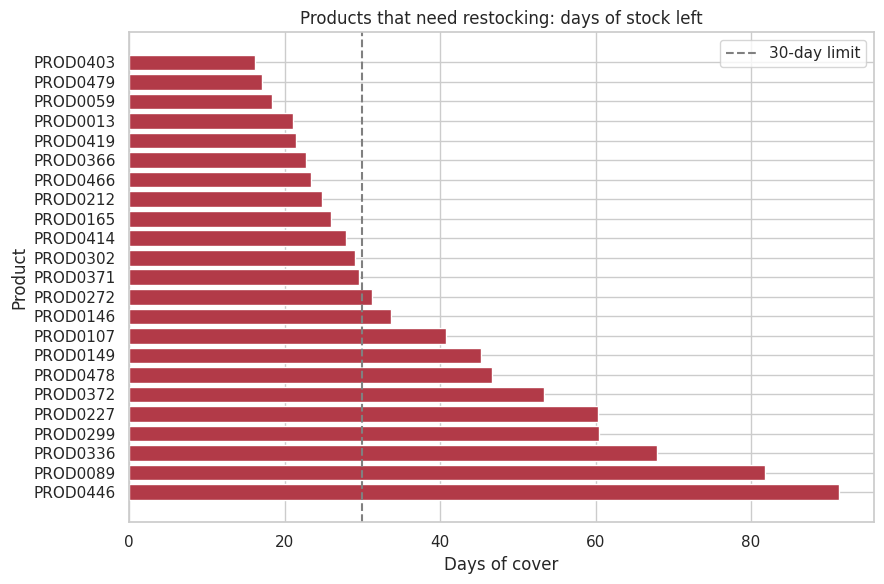

ANSWER: 23 products need restocking now (21 are at or below their reorder level). The most urgent are PROD0403, PROD0479, PROD0059. Ordering enough for 60 days of sales needs 322 units costing about 7,859,732. The opposite problem is bigger: 307 products (61%) have more than a year of stock, tying up 2,716,869,461.


In [49]:
restock = inventory_analysis_df[inventory_analysis_df['inventory_status'] == 'Low'].copy()
restock['units_to_order'] = np.ceil(np.maximum(0, 60 * restock['daily_demand'] - restock['stock_on_hand'])).astype(int)      # enough to last 60 days
restock['cost_to_order'] = restock['units_to_order'] * restock['cost_price']
restock = restock.sort_values('days_of_cover')
display(restock[['product_id', 'product_name', 'store_label', 'stock_on_hand', 'reorder_level', 'days_of_cover', 'units_to_order', 'cost_to_order']].round(1).style.format({'cost_to_order': '{:,.0f}'}))

plt.figure(figsize=(9, 6))
plt.barh(restock['product_id'][::-1], restock['days_of_cover'][::-1], color='#b23a48')
plt.axvline(30, linestyle='--', color='grey', label='30-day limit')
plt.title('Products that need restocking: days of stock left')
plt.xlabel('Days of cover')
plt.ylabel('Product')
plt.legend()
save_chart('15_restock_list.png')

overstock = inventory_analysis_df[inventory_analysis_df['inventory_status'] == 'High']
print(f"ANSWER: {len(restock)} products need restocking now ({(restock['stock_on_hand'] <= restock['reorder_level']).sum()} are at or below their reorder level). "
      f"The most urgent are {', '.join(restock['product_id'].head(3))}. Ordering enough for 60 days of sales needs {restock['units_to_order'].sum():,} units costing about {restock['cost_to_order'].sum():,.0f}. "
      f"The opposite problem is bigger: {len(overstock)} products ({len(overstock) / len(inventory_analysis_df):.0%}) have more than a year of stock, tying up {overstock['stock_value_at_cost'].sum():,.0f}.")

## Q9. Which regions underperform?
Regions have different numbers of stores, so compare **revenue per store**.

,revenue,stores,revenue_per_store,vs_average_%
region,,,,
West,"389,023,533",4,"97,255,883",-2.6%
East,"694,202,855",7,"99,171,836",-0.7%
South,"805,370,701",8,"100,671,338",+0.8%
North,"608,227,294",6,"101,371,216",+1.5%


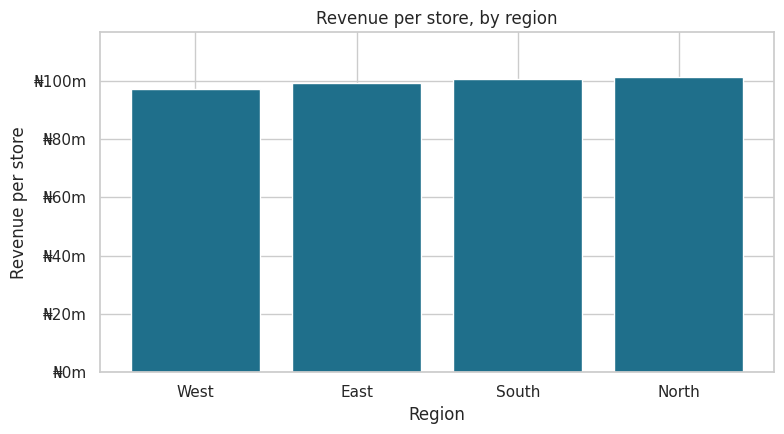

Cities that appear in more than one region:


region,East,North,South,West
store_city,,,,
Abeokuta,1,0,1,0
Abuja,1,1,2,0
Asaba,0,1,1,1
Ibadan,2,1,1,0
Kaduna,1,0,1,1
Lagos,1,1,1,1


ANSWER: By total revenue the West region is lowest, but it has only 4 stores (average 6.2 per region). Per store, the lowest region is West (-2.6% vs the average store) and the highest is North (+1.5%). By state the lowest per store is Kano. These gaps are small, and the region field is unreliable (the same city appears in several regions), so no region clearly underperforms.


In [50]:
region_table = completed_df.groupby('region').agg(revenue=('line_total', 'sum'), stores=('store_id', 'nunique'))
region_table['revenue_per_store'] = region_table['revenue'] / region_table['stores']
region_table['vs_average_%'] = (region_table['revenue_per_store'] / completed_df.groupby('store_id')['line_total'].sum().mean() - 1) * 100
display(region_table.sort_values('revenue_per_store').style.format({'revenue': '{:,.0f}', 'revenue_per_store': '{:,.0f}', 'vs_average_%': '{:+.1f}%'}))

plt.figure(figsize=(8, 4.5))
r = region_table.sort_values('revenue_per_store')
plt.bar(r.index, r['revenue_per_store'], color=COLOUR)
plt.ylim(0, r['revenue_per_store'].max() * 1.15)
plt.gca().yaxis.set_major_formatter(mtick.FuncFormatter(millions))
plt.title('Revenue per store, by region')
plt.xlabel('Region')
plt.ylabel('Revenue per store')
save_chart('16_revenue_per_store_by_region.png')

print('Cities that appear in more than one region:')
display(pd.crosstab(stores_df['store_city'], stores_df['region']).loc[lambda t: (t > 0).sum(axis=1) > 1])
lowest_state = by_state['revenue_per_store'].idxmin()
lowest_total = region_table['revenue'].idxmin()
print(f"ANSWER: By total revenue the {lowest_total} region is lowest, but it has only {region_table.loc[lowest_total, 'stores']} stores (average {region_table['stores'].mean():.1f} per region). Per store, the lowest region is {region_table['revenue_per_store'].idxmin()} "
      f"({region_table['vs_average_%'].min():+.1f}% vs the average store) and the highest is {region_table['revenue_per_store'].idxmax()} ({region_table['vs_average_%'].max():+.1f}%). "
      f"By state the lowest per store is {lowest_state}. These gaps are small, and the region field is unreliable (the same city appears in several regions), so no region clearly underperforms.")

## Q10. What patterns could support predictive modelling?
A model can only learn from patterns that exist. A simple test: does the **return rate** change across groups? If it is the same for every group, those columns cannot help predict returns.

In [51]:
rows = []
for col in ['category', 'sales_channel', 'payment_method', 'discount', 'quantity', 'customer_segment', 'age_group', 'order_status']:
    rates = sales_df.groupby(col, observed=True)['returned'].mean() * 100
    rows.append((col, rates.min(), rates.max(), rates.max() - rates.min()))
return_patterns = pd.DataFrame(rows, columns=['grouped_by', 'lowest_return_rate_%', 'highest_return_rate_%', 'spread_points']).round(2)
display(return_patterns)

,grouped_by,lowest_return_rate_%,highest_return_rate_%,spread_points
0,category,4.58,5.13,0.55
1,sales_channel,4.77,5.00,0.22
2,payment_method,4.78,4.94,0.16
3,discount,4.73,5.16,0.43
4,quantity,4.56,5.14,0.58
5,customer_segment,4.76,5.10,0.34
6,age_group,4.50,5.49,0.99
7,order_status,4.83,4.98,0.16


**Answer to Q10.** Honestly, the data holds very few patterns that a model could learn:

* **Return rate** is about 5% in every group (table above), so channel, payment, category, discount, age and segment do not help predict returns. Returns even occur at the same rate on cancelled and pending orders, which should be impossible.
* **Sales** are flat across months, stores, regions and categories, so there is no trend or seasonality to forecast yet (only one year of data).
* **Customer spend** is the same across segments and ages.
* **Structural patterns do exist:** `line_total` follows from quantity and price, and `selling_price` follows from `cost_price` (r ≈ 0.96).

**What the data can support now** and what needs better data:

| Machine learning idea | Possible now? | What is needed |
|---|---|---|
| Detecting unusual transactions (below-cost sales, refunds above sale value) | **Yes** – rules or simple statistics | Nothing more |
| Customer segmentation (e.g. K-Means on recency, frequency, spend) | Partly | More behaviour data to get meaningful groups |
| Inventory planning (days of cover) | Yes, as simple rules | Stock per store and a longer sales history |
| Sales forecasting | Not yet | 2–3 years of history |
| Return prediction | No | Product quality, delivery and customer-history data; correct return dates |
| Churn prediction / product recommendation | No | Multi-year history; multi-item baskets |

---
# Summary of Findings and Recommendations

In [52]:
status_share = sales_df.groupby('order_status', observed=True)['line_total'].sum() / sales_df['line_total'].sum() * 100
print('FIVE KEY INSIGHTS')
print(f"1. Only {status_share['Completed']:.0f}% of booked order value is Completed; {status_share['Cancelled']:.0f}% is Cancelled and {status_share['Pending']:.0f}% is Pending.")
print(f"2. Stores, regions, customer segments, categories and months perform alike; differences are small and change with the base used.")
print(f"3. Pricing data is unreliable: {sales_df['flag_below_cost'].mean():.0%} of orders were sold below cost price and the price charged is unrelated to the price list.")
print(f"4. Return records are unreliable: {returns_df['flag_return_before_order'].mean():.0%} are dated before the order and {returns_df['flag_order_not_completed'].mean():.0%} belong to orders that were never completed.")
print(f"5. Inventory is unbalanced: {len(restock)} products need restocking, but {len(overstock)} hold over a year of stock worth {overstock['stock_value_at_cost'].sum():,.0f}.")

FIVE KEY INSIGHTS
1. Only 33% of booked order value is Completed; 34% is Cancelled and 33% is Pending.
2. Stores, regions, customer segments, categories and months perform alike; differences are small and change with the base used.
3. Pricing data is unreliable: 24% of orders were sold below cost price and the price charged is unrelated to the price list.
4. Return records are unreliable: 50% are dated before the order and 67% belong to orders that were never completed.
5. Inventory is unbalanced: 23 products need restocking, but 307 hold over a year of stock worth 2,716,869,461.


**Five recommendations**
1. Find out why one-third of orders are cancelled and one-third stay pending, and report **Completed** revenue as the main KPI.
2. Confirm what the *Discount* column means (percentage or naira) and restate revenue; make till prices follow the price list and review below-cost sales.
3. Add rules to the returns process (return date after the order date, refund not above the sale, only completed orders can be returned).
4. Restock the urgent products and set a maximum stock level so money is not tied up in over a year of stock.
5. Before machine learning: write a proper data dictionary, collect more history, and record stock per store, delivery time and product quality.

**Suggested machine-learning problems** (from Q10): anomaly detection (feasible now), customer segmentation, inventory planning, then sales forecasting and return prediction once the data improves.